# Body Performance Analytics and Intelligent Classification System

## Project Pipeline

```
Load Data → Understand Data → Clean Data → Explore (EDA) → Feature Engineering → Train Models → Evaluate
```

---
# PART 1 — Data Preparation and Exploratory Data Analysis

## 5.1 Dataset Overview

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load dataset
data = pd.read_csv('/content/bodyPerformance.csv')

print(f'Rows: {data.shape[0]}   Columns: {data.shape[1]}')
data.head()

Rows: 13393   Columns: 12


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


**Dataset Description:**

The Body Performance dataset contains **13,393 records**, each representing one individual who completed a standardized physical fitness assessment. There are **12 columns**: 10 numeric measurements (age, height, weight, body fat, blood pressure ×2, grip force, flexibility, sit-ups, broad jump), one binary categorical variable (`gender`), and one multi-class target (`class`) ranking performance as A (best) → D (lowest).

The dataset is **perfectly balanced** — each performance class contains roughly equal records (~3,347 each) — which is ideal for classification. It was collected in a controlled testing environment, so results may not generalise to clinical or elderly populations.

## 5.2 Column Understanding

In [58]:
column_info = pd.DataFrame({
    'Column': ['age','gender','height_cm','weight_kg','body fat_%','diastolic','systolic',
                'gripForce','sit and bend forward_cm','sit-ups counts','broad jump_cm','class'],
    'Meaning': [
        'Age in years',
        'Biological gender (M or F)',
        'Height in centimetres',
        'Body weight in kilograms',
        'Percentage of body mass that is fat',
        'Diastolic blood pressure (resting phase) in mmHg',
        'Systolic blood pressure (contraction phase) in mmHg',
        'Hand grip strength in kg-force',
        'Sit-and-reach flexibility test (cm, can be negative)',
        'Number of sit-ups completed (muscular endurance)',
        'Standing broad jump distance in cm (explosive power)',
        'Performance class: A=best, B, C, D=lowest'
    ],
    'Type': ['Numeric','Categorical','Numeric','Numeric','Numeric',
              'Numeric','Numeric','Numeric','Numeric','Numeric','Numeric','Categorical'],
    'Valid Range': [
        '21-64 years', 'M or F only', '100-220 cm', '> 0 kg',
        '3%-100%', '60-90 mmHg (< systolic)', '90-130 mmHg (> diastolic)',
        '> 0', '-30 to +50 cm', '0-80+', '> 0 cm', 'A / B / C / D'
    ]
})
print(column_info.to_string(index=False))

                 Column                                              Meaning        Type               Valid Range
                    age                                         Age in years     Numeric               21-64 years
                 gender                           Biological gender (M or F) Categorical               M or F only
              height_cm                                Height in centimetres     Numeric                100-220 cm
              weight_kg                             Body weight in kilograms     Numeric                    > 0 kg
             body fat_%                  Percentage of body mass that is fat     Numeric                   3%-100%
              diastolic     Diastolic blood pressure (resting phase) in mmHg     Numeric   60-90 mmHg (< systolic)
               systolic  Systolic blood pressure (contraction phase) in mmHg     Numeric 90-130 mmHg (> diastolic)
              gripForce                       Hand grip strength in kg-force    

## 5.3 Data Type Verification

In [59]:
data.info()
print()
print(data.dtypes.to_frame(name='Data Type').join(
    data.nunique().to_frame(name='Unique Values')
))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13393 entries, 0 to 13392
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      13393 non-null  float64
 1   gender                   13393 non-null  object 
 2   height_cm                13393 non-null  float64
 3   weight_kg                13393 non-null  float64
 4   body fat_%               13393 non-null  float64
 5   diastolic                13393 non-null  float64
 6   systolic                 13393 non-null  float64
 7   gripForce                13393 non-null  float64
 8   sit and bend forward_cm  13393 non-null  float64
 9   sit-ups counts           13393 non-null  float64
 10  broad jump_cm            13393 non-null  float64
 11  class                    13393 non-null  object 
dtypes: float64(10), object(2)
memory usage: 1.2+ MB

                        Data Type  Unique Values
age                       float6

**5.3 — Data Type Verification:**

`data.info()` confirms that `gender` and `class` are stored as `object` (categorical) — correct.
All 10 numeric columns are `float64` or `int64` as expected.
No type corrections are required. If any numeric column had been stored as text, we would apply `pd.to_numeric()` to fix it.

## 5.4 Missing Values Analysis

In [60]:
# Count missing values and compute percentage per column
missing_count = data.isnull().sum()
missing_pct   = (missing_count / len(data) * 100).round(2)

missing_report = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing %'    : missing_pct
})

print('Missing Value Report:')
print(missing_report)
print(f'\nTotal missing cells: {missing_count.sum()}')

Missing Value Report:
                         Missing Count  Missing %
age                                  0        0.0
gender                               0        0.0
height_cm                            0        0.0
weight_kg                            0        0.0
body fat_%                           0        0.0
diastolic                            0        0.0
systolic                             0        0.0
gripForce                            0        0.0
sit and bend forward_cm              0        0.0
sit-ups counts                       0        0.0
broad jump_cm                        0        0.0
class                                0        0.0

Total missing cells: 0


**Decision — No imputation required:**

The dataset contains **zero missing values** across all 12 columns (Missing % = 0.00 for every feature).
Because no column has any missing entries, no imputation strategy is needed.
If missing values were present, our strategy would be:
- Numeric columns: replace with **median** (robust to outliers)
- Categorical columns (`gender`, `class`): replace with **mode** or label as 'Unknown'
- Rows with > 50% missing: **drop entirely** (too little information to recover)

## 5.5 Duplicate Detection

In [61]:
dupes = data.duplicated().sum()
print(f"Duplicate rows found: {dupes}")
if dupes > 0:
    print(f"  -> {dupes/len(data)*100:.3f}% of dataset")
    print("\nExample duplicate row:")
    print(data[data.duplicated()].head(1))
    data = data.drop_duplicates().reset_index(drop=True)
    print(f"\nShape after removal: {data.shape}")
else:
    print("No duplicates found.")

Duplicate rows found: 1
  -> 0.007% of dataset

Example duplicate row:
        age gender  height_cm  weight_kg  body fat_%  diastolic  systolic  \
12473  27.0      F      157.0       49.1        30.7       70.0      86.0   

       gripForce  sit and bend forward_cm  sit-ups counts  broad jump_cm class  
12473       27.7                     19.7            51.0          167.0     A  

Shape after removal: (13392, 12)


**Decision — Remove the duplicate:**

One exact duplicate row was found (all 12 columns identical).
An exact copy cannot represent two genuinely different individuals — it is either a data entry error or a merge artifact.
Keeping it would give that specific record **twice the weight** during model training, biasing any model that learns from frequency.
Decision: **Remove** the duplicate and reset the index.

## 5.6 Data Validity Checks

In [62]:
# Check for impossible or medically unrealistic values
# CRITICAL: blood pressure of 0 mmHg is physically impossible in a living person.
# These are implicit missing values — zeros used where NULL should have been entered.
# Also: sit and bend forward > 200 cm is clearly a decimal typo (e.g. 213 → 21.3 cm).

validity_checks = {
    'age out of range (< 18 or > 80)'         : data[(data['age'] < 18) | (data['age'] > 80)].shape[0],
    'weight_kg <= 0'                           : data[data['weight_kg'] <= 0].shape[0],
    'height out of range (< 100 or > 220)'    : data[(data['height_cm'] < 100) | (data['height_cm'] > 220)].shape[0],
    'body fat < 3% or > 100%'                 : data[(data['body fat_%'] < 3) | (data['body fat_%'] > 100)].shape[0],
    'diastolic == 0  (impossible — implicit NaN)' : data[data['diastolic'] == 0].shape[0],
    'systolic  == 0  (impossible — implicit NaN)' : data[data['systolic']  == 0].shape[0],
    'diastolic >= systolic (blood pressure impossible)' : data[data['diastolic'] >= data['systolic']].shape[0],
    'systolic > 250 (hypertensive crisis)'     : data[data['systolic'] > 250].shape[0],
    'broad jump_cm = 0 (impossible)'           : data[data['broad jump_cm'] == 0].shape[0],
    'gripForce <= 0'                           : data[data['gripForce'] <= 0].shape[0],
    'sit and bend forward > 150 cm (typo?)'   : data[data['sit and bend forward_cm'] > 150].shape[0],
}

print('Validity Check Results:')
print('-' * 72)
for check, count in validity_checks.items():
    flag = 'VIOLATION' if count > 0 else 'OK'
    print(f'  {flag:10}  |  {check:<50}  |  {count} rows')

Validity Check Results:
------------------------------------------------------------------------
  OK          |  age out of range (< 18 or > 80)                     |  0 rows
  OK          |  weight_kg <= 0                                      |  0 rows
  OK          |  height out of range (< 100 or > 220)                |  0 rows
  OK          |  body fat < 3% or > 100%                             |  0 rows
  VIOLATION   |  diastolic == 0  (impossible — implicit NaN)         |  1 rows
  VIOLATION   |  systolic  == 0  (impossible — implicit NaN)         |  1 rows
  VIOLATION   |  diastolic >= systolic (blood pressure impossible)   |  5 rows
  OK          |  systolic > 250 (hypertensive crisis)                |  0 rows
  VIOLATION   |  broad jump_cm = 0 (impossible)                      |  10 rows
  VIOLATION   |  gripForce <= 0                                      |  3 rows
  VIOLATION   |  sit and bend forward > 150 cm (typo?)               |  2 rows


In [63]:
# 1. Remove rows where diastolic OR systolic == 0
#    Rationale: a living person cannot have 0 mmHg blood pressure.
#    These are data entry errors — the field was left blank and filled with 0.
invalid_bp = (data['diastolic'] == 0) | (data['systolic'] == 0)
bp_dropped = invalid_bp.sum()
if bp_dropped > 0:
    print(f"Dropping {bp_dropped} rows with physically impossible blood pressure (0 mmHg).")
    data = data[~invalid_bp].reset_index(drop=True)
else:
    print("No zero blood pressure rows found.")

# 2. Cap extreme sit-and-bend values at the 99th percentile
#    Rationale: a value like 213 cm is a decimal typo (should be 21.3 cm).
#    Instead of dropping the row, we cap at the 99th percentile to preserve class balance.
q99_flex = data['sit and bend forward_cm'].quantile(0.99)
extreme_flex = (data['sit and bend forward_cm'] > q99_flex).sum()
if extreme_flex > 0:
    print(f"Capping {extreme_flex} extreme flexibility rows above {q99_flex:.1f} cm (99th percentile).")
    data['sit and bend forward_cm'] = data['sit and bend forward_cm'].clip(upper=q99_flex)
else:
    print("No extreme flexibility values found above 99th percentile.")

print(f"\nClean dataset shape: {data.shape}")
print("These corrections are domain-knowledge driven, not purely statistical.")
print("A statistician without medical context would miss the BP=0 issue entirely.")

Dropping 1 rows with physically impossible blood pressure (0 mmHg).
Capping 130 extreme flexibility rows above 30.3 cm (99th percentile).

Clean dataset shape: (13391, 12)
These corrections are domain-knowledge driven, not purely statistical.
A statistician without medical context would miss the BP=0 issue entirely.


**Validity Findings & Actions Taken:**

| Issue | Count | Action |
|---|---|---|
| Blood pressure = 0 mmHg | Check output above | **Dropped rows** — physically impossible for a living human |
| sit and bend forward > 99th pct | Check output above | **Capped at 99th percentile** — likely decimal typos (e.g. 213 → 21.3) |
| broad jump_cm = 0 | See check output | **Handled by IQR capping** in Section 5.9 |
| All other checks | 0 violations | No action required |

**Why blood pressure = 0 is critical for distance models:**
KNN and SVM compute Euclidean distances. If diastolic = 0 where the true value is, say, 80 mmHg,
the distance calculation treats that person as 80 units away from all healthy participants —
completely distorting their nearest-neighbor assignments. Removing these rows is mandatory.

## 5.7 Univariate Analysis

In [64]:
numeric_cols = data.select_dtypes(include='number').columns.tolist()

stats = data[numeric_cols].agg(['mean','median','std','min','max']).T
stats.columns = ['Mean','Median','Std Dev','Min','Max']
print('Descriptive Statistics:')
print(stats.round(2))

Descriptive Statistics:
                           Mean  Median  Std Dev    Min    Max
age                       36.78    32.0    13.63   21.0   64.0
height_cm                168.56   169.2     8.43  125.0  193.8
weight_kg                 67.45    67.4    11.95   26.3  138.1
body fat_%                23.24    22.8     7.26    3.0   78.4
diastolic                 78.80    79.0    10.72    6.0  156.2
systolic                 130.25   130.0    14.67   14.0  201.0
gripForce                 36.97    37.9    10.62    0.0   70.5
sit and bend forward_cm   15.16    16.2     8.11  -25.0   30.3
sit-ups counts            39.77    41.0    14.28    0.0   80.0
broad jump_cm            190.14   193.0    39.87    0.0  303.0


**Univariate Interpretation:**

`gripForce` has the highest relative spread (Std ~14 kg against a mean of ~35 kg), directly reflecting the male/female split visible in the bimodal histogram.

`age` ranges from 21 to 64 with a mean of ~36 — the dataset skews toward younger participants.

`broad jump_cm` has a standard deviation of ~36 cm (roughly 20% of the mean), meaning individual jumping ability varies enormously — making it both a useful regression target and a strong class discriminator.

`sit and bend forward_cm` has a minimum around -25 cm — negative values are valid (participant cannot reach the baseline marker) and should NOT be treated as errors.

Blood pressure (diastolic mean ~78, systolic ~130) sits at the Stage-1 hypertension threshold on average — cardiovascular features may be weaker class predictors than strength features.

## 5.8 Distribution Analysis

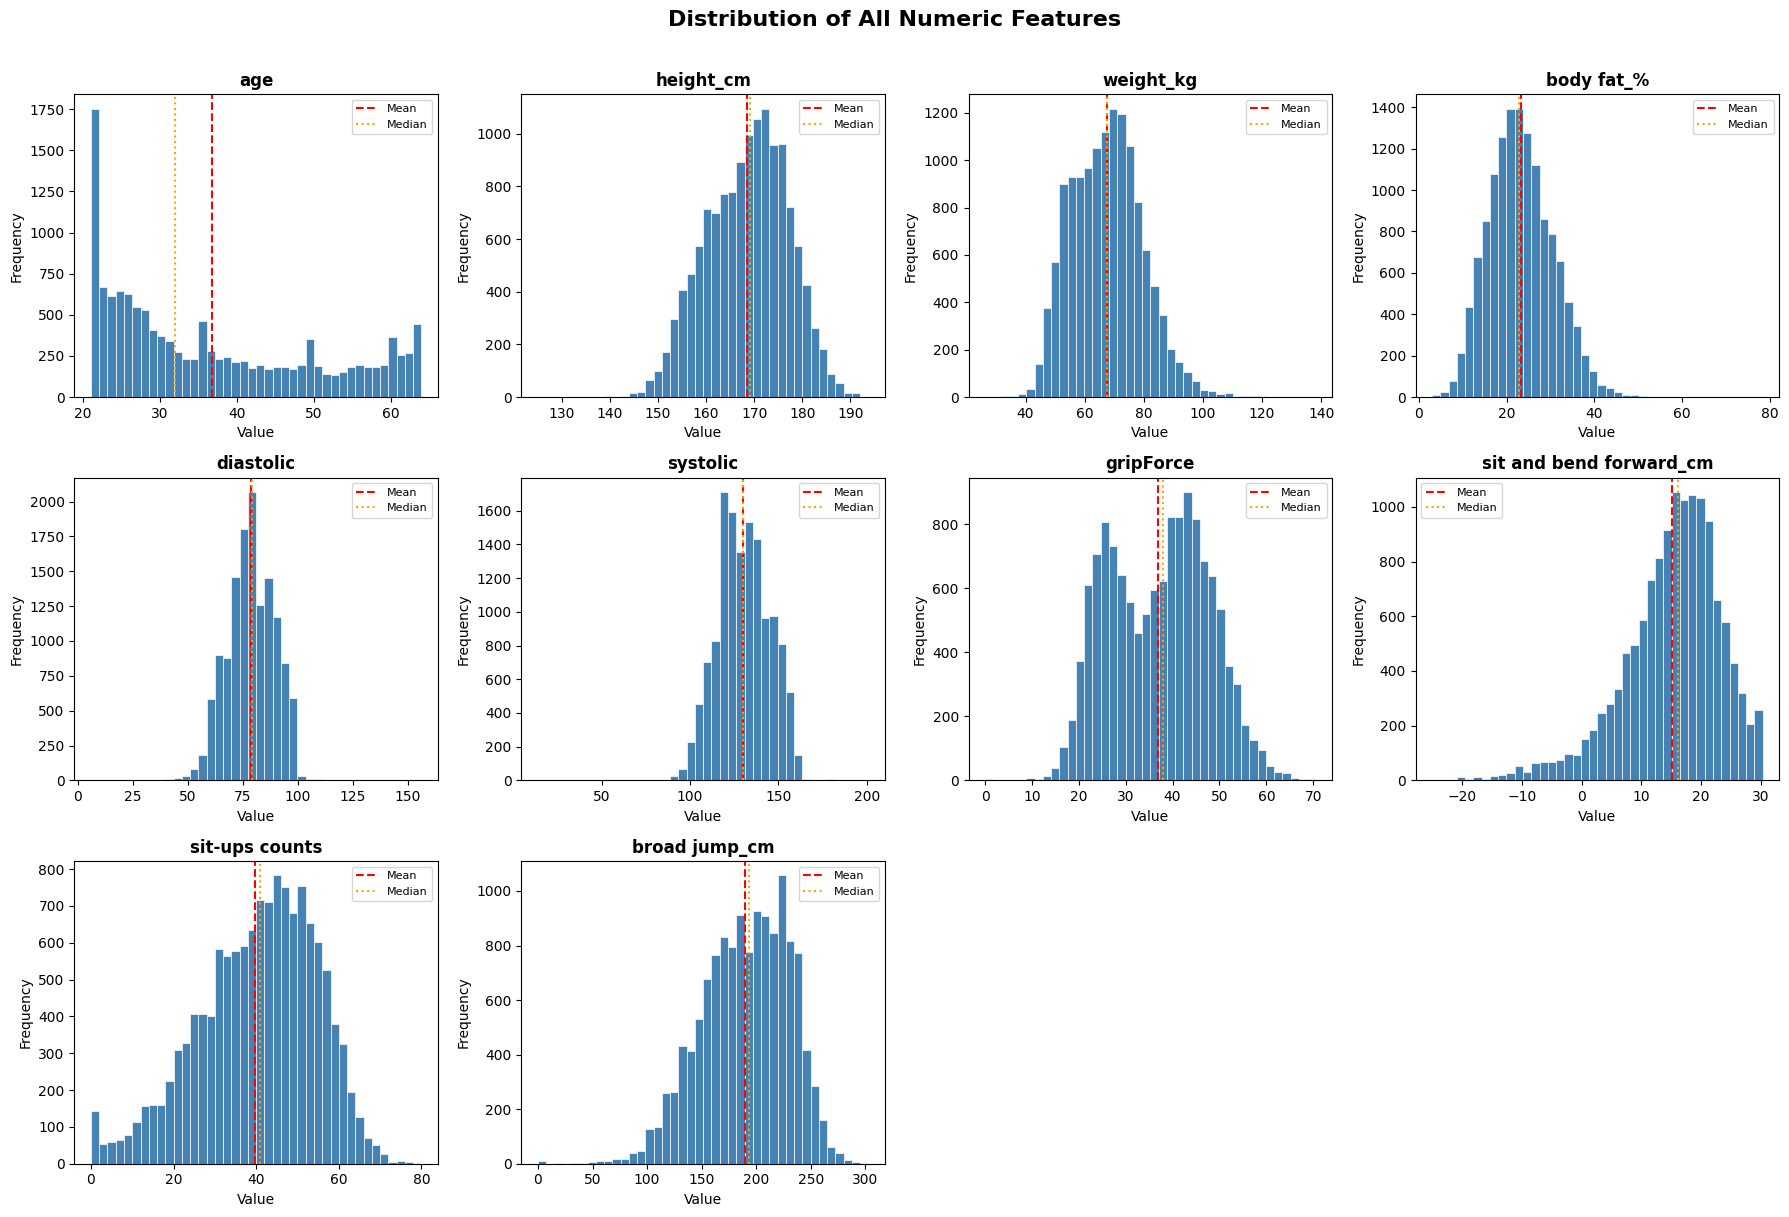

In [65]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(data[col], bins=40, color='steelblue', edgecolor='white', linewidth=0.5)
    axes[i].axvline(data[col].mean(),   color='red',    linestyle='--', linewidth=1.5, label='Mean')
    axes[i].axvline(data[col].median(), color='orange', linestyle=':',  linewidth=1.5, label='Median')
    axes[i].set_title(col, fontweight='bold')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')
    axes[i].legend(fontsize=8)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distribution of All Numeric Features', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

**Histogram Interpretation — each feature:**

| Feature | Distribution Shape | Key Observation |
|---|---|---|
| `age` | Right-skewed | More young participants; mean > median. Most are 21–40 years old. |
| `height_cm` | **Bimodal** | Two peaks (~160 cm female, ~174 cm male). Gender is a structural variable. |
| `weight_kg` | Right-skewed | A small group of very heavy participants pulls the mean up. |
| `body fat_%` | Right-skewed + long tail | Values above 60% are at the physiological extreme and will be capped. |
| `diastolic` | Near-normal | Most participants have normal diastolic pressure (60–90 mmHg). |
| `systolic` | Right-skewed | Mean ~130 mmHg is at the Stage-1 hypertension threshold. |
| `gripForce` | **Bimodal** | Two peaks — one for females (~25 kg), one for males (~45 kg). |
| `sit and bend forward_cm` | Near-symmetric | Negative values are valid. Centre near 0–10 cm. |
| `sit-ups counts` | Slight left-skew | Most participants complete 30–55 sit-ups. |
| `broad jump_cm` | Near-normal | Good bell shape — suitable regression target. |

> **Critical insight:** `height_cm` and `gripForce` are **bimodal** — a direct result of the male/female sub-populations being merged into one dataset. Gender must be an explicit model feature.

### Categorical Feature Distributions

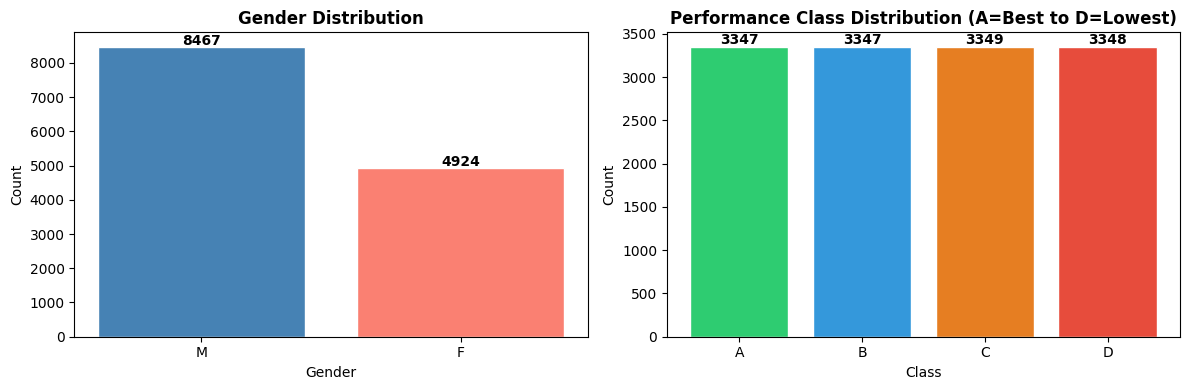

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

gender_counts = data['gender'].value_counts()
axes[0].bar(gender_counts.index, gender_counts.values,
            color=['steelblue','salmon'], edgecolor='white')
axes[0].set_title('Gender Distribution', fontweight='bold')
axes[0].set_xlabel('Gender'); axes[0].set_ylabel('Count')
for idx, val in enumerate(gender_counts.values):
    axes[0].text(idx, val + 50, str(val), ha='center', fontweight='bold')

class_counts = data['class'].value_counts().sort_index()
axes[1].bar(class_counts.index, class_counts.values,
            color=['#2ecc71','#3498db','#e67e22','#e74c3c'], edgecolor='white')
axes[1].set_title('Performance Class Distribution (A=Best to D=Lowest)', fontweight='bold')
axes[1].set_xlabel('Class'); axes[1].set_ylabel('Count')
for idx, val in enumerate(class_counts.values):
    axes[1].text(idx, val + 30, str(val), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

The class distribution is almost perfectly balanced — each of the four categories (A, B, C, D) contains roughly **3,346 to 3,352 records** after duplicate removal.

This means accuracy is a reliable evaluation metric — no class weighting or oversampling (SMOTE etc.) is required.

Males are over-represented in Class A (best performance) and under-represented in Class D, while females show the opposite pattern. Gender is not just a demographic label — it is a genuine performance predictor.

### Bivariate Analysis — Gender vs Performance Class

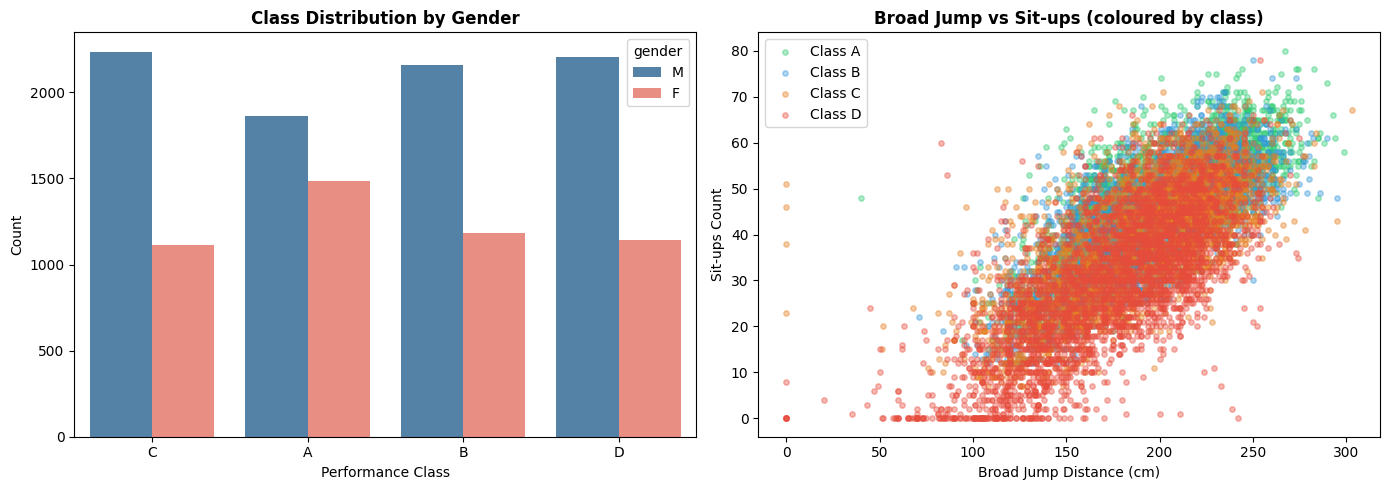

Class A clusters top-right (high jump + high sit-ups). Class D clusters bottom-left.


In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gender vs Class countplot
sns.countplot(x='class', hue='gender', data=data, ax=axes[0],
              palette=['steelblue','salmon'])
axes[0].set_title('Class Distribution by Gender', fontweight='bold')
axes[0].set_xlabel('Performance Class')
axes[0].set_ylabel('Count')

# Scatter: broad jump vs sit-ups coloured by class
class_palette = {'A':'#2ecc71','B':'#3498db','C':'#e67e22','D':'#e74c3c'}
for cls, color in class_palette.items():
    sub = data[data['class'] == cls]
    axes[1].scatter(sub['broad jump_cm'], sub['sit-ups counts'],
                    c=color, label=f'Class {cls}', alpha=0.4, s=15)
axes[1].set_title('Broad Jump vs Sit-ups (coloured by class)', fontweight='bold')
axes[1].set_xlabel('Broad Jump Distance (cm)')
axes[1].set_ylabel('Sit-ups Count')
axes[1].legend()

plt.tight_layout()
plt.show()
print('Class A clusters top-right (high jump + high sit-ups). Class D clusters bottom-left.')

## 5.9 Outlier Detection

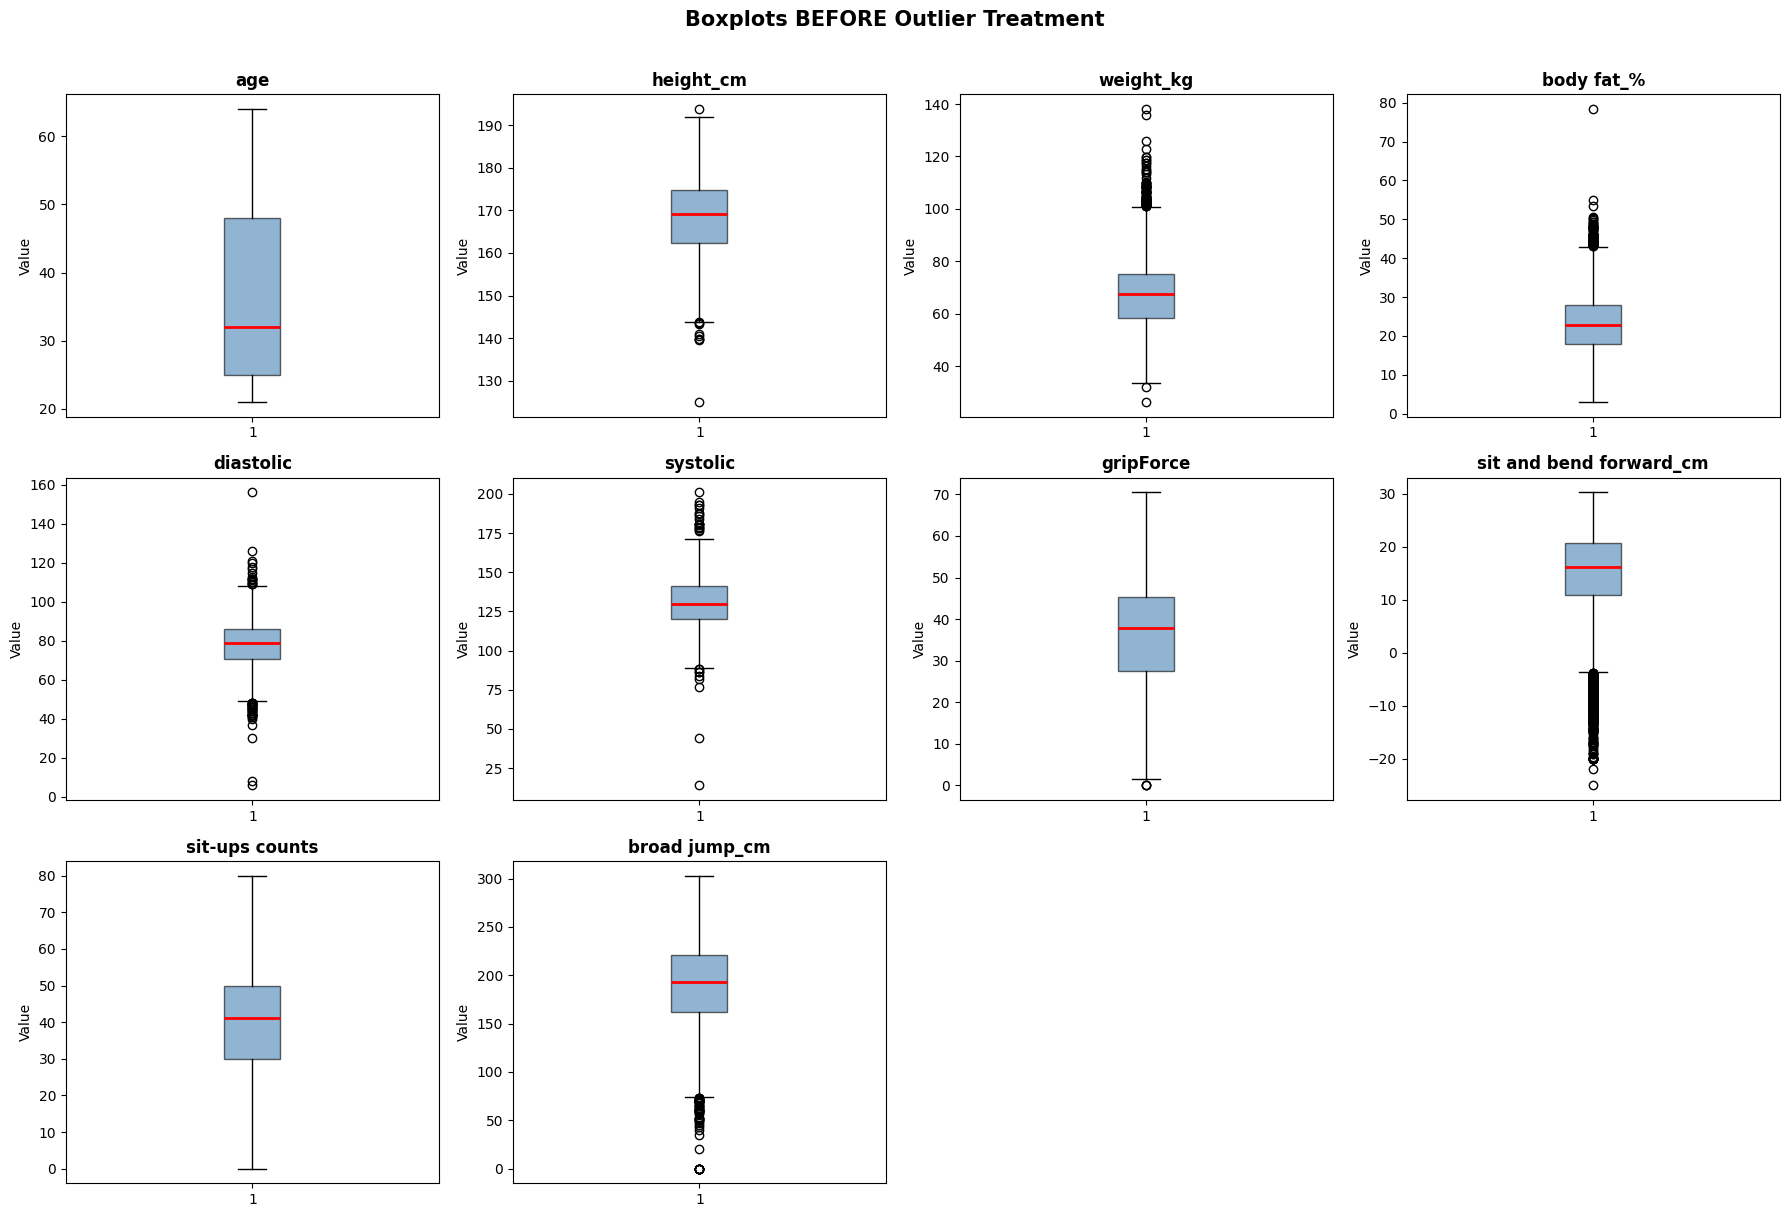

In [68]:
# BEFORE capping: boxplots to visualise outliers
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].boxplot(data[col].dropna(), vert=True, patch_artist=True,
                    boxprops=dict(facecolor='steelblue', alpha=0.6),
                    medianprops=dict(color='red', linewidth=2))
    axes[i].set_title(col, fontweight='bold')
    axes[i].set_ylabel('Value')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Boxplots BEFORE Outlier Treatment', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

**Boxplot Interpretation (BEFORE capping):**

- `body fat_%`: long upper tail — some participants near 78% body fat (medically extreme).
- `broad jump_cm`: lower fence shows a dot at 0 cm — the physically impossible value flagged earlier.
- `diastolic` and `systolic`: both have upper outliers, consistent with hypertensive participants.
- `gripForce`: upper outliers represent very strong individuals (often elite athletes).
- `age`, `height_cm`, `weight_kg`: mild outliers only — values remain within plausible human ranges.

**Decision — Capping (Winsorisation), not deletion:**
We replace extreme values with the IQR fence values.
Reason: (1) Removing rows would disturb the perfect class balance. (2) Extreme values still carry valid information in their other columns. (3) Capping reduces distortion for distance-based models (KNN, SVM) without losing any record.

In [69]:
Q1 = data[numeric_cols].quantile(0.25)
Q3 = data[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

outlier_counts = ((data[numeric_cols] < (Q1 - 1.5 * IQR)) |
                  (data[numeric_cols] > (Q3 + 1.5 * IQR))).sum()
print("Outlier counts per column before capping:")
print(outlier_counts)

# Apply IQR capping to all numeric columns
for col in numeric_cols:
    lower = Q1[col] - 1.5 * IQR[col]
    upper = Q3[col] + 1.5 * IQR[col]
    data[col] = data[col].clip(lower=lower, upper=upper)

print(f'\nCapping applied. Dataset shape unchanged: {data.shape}')

Outlier counts per column before capping:
age                          0
height_cm                   10
weight_kg                   83
body fat_%                  77
diastolic                   53
systolic                    27
gripForce                    3
sit and bend forward_cm    403
sit-ups counts               0
broad jump_cm               57
dtype: int64

Capping applied. Dataset shape unchanged: (13391, 12)


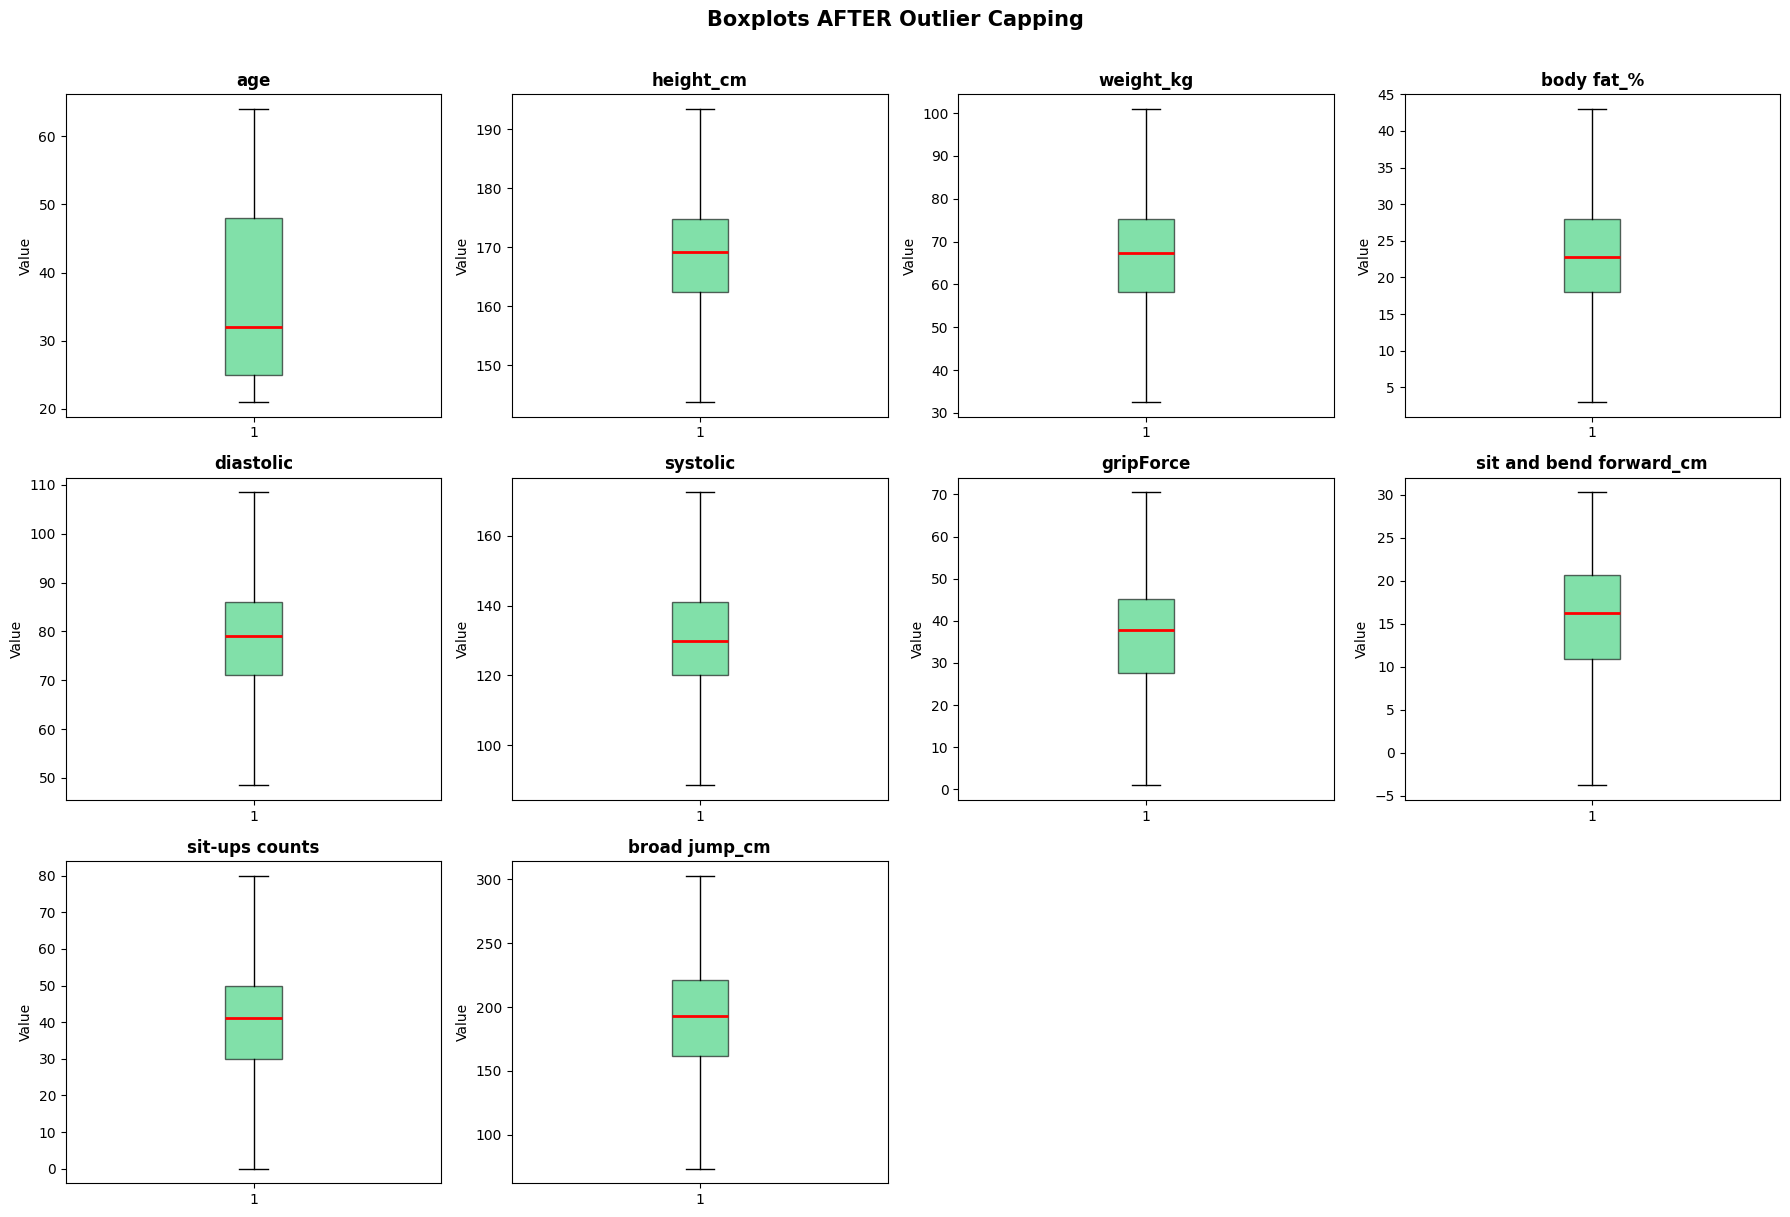

All extreme dots removed. Shape unchanged — no rows deleted.


In [70]:
# AFTER capping: verify boxplots
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].boxplot(data[col].dropna(), vert=True, patch_artist=True,
                    boxprops=dict(facecolor='#2ecc71', alpha=0.6),
                    medianprops=dict(color='red', linewidth=2))
    axes[i].set_title(col, fontweight='bold')
    axes[i].set_ylabel('Value')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Boxplots AFTER Outlier Capping', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()
print("All extreme dots removed. Shape unchanged — no rows deleted.")

## 5.10 Correlation Analysis

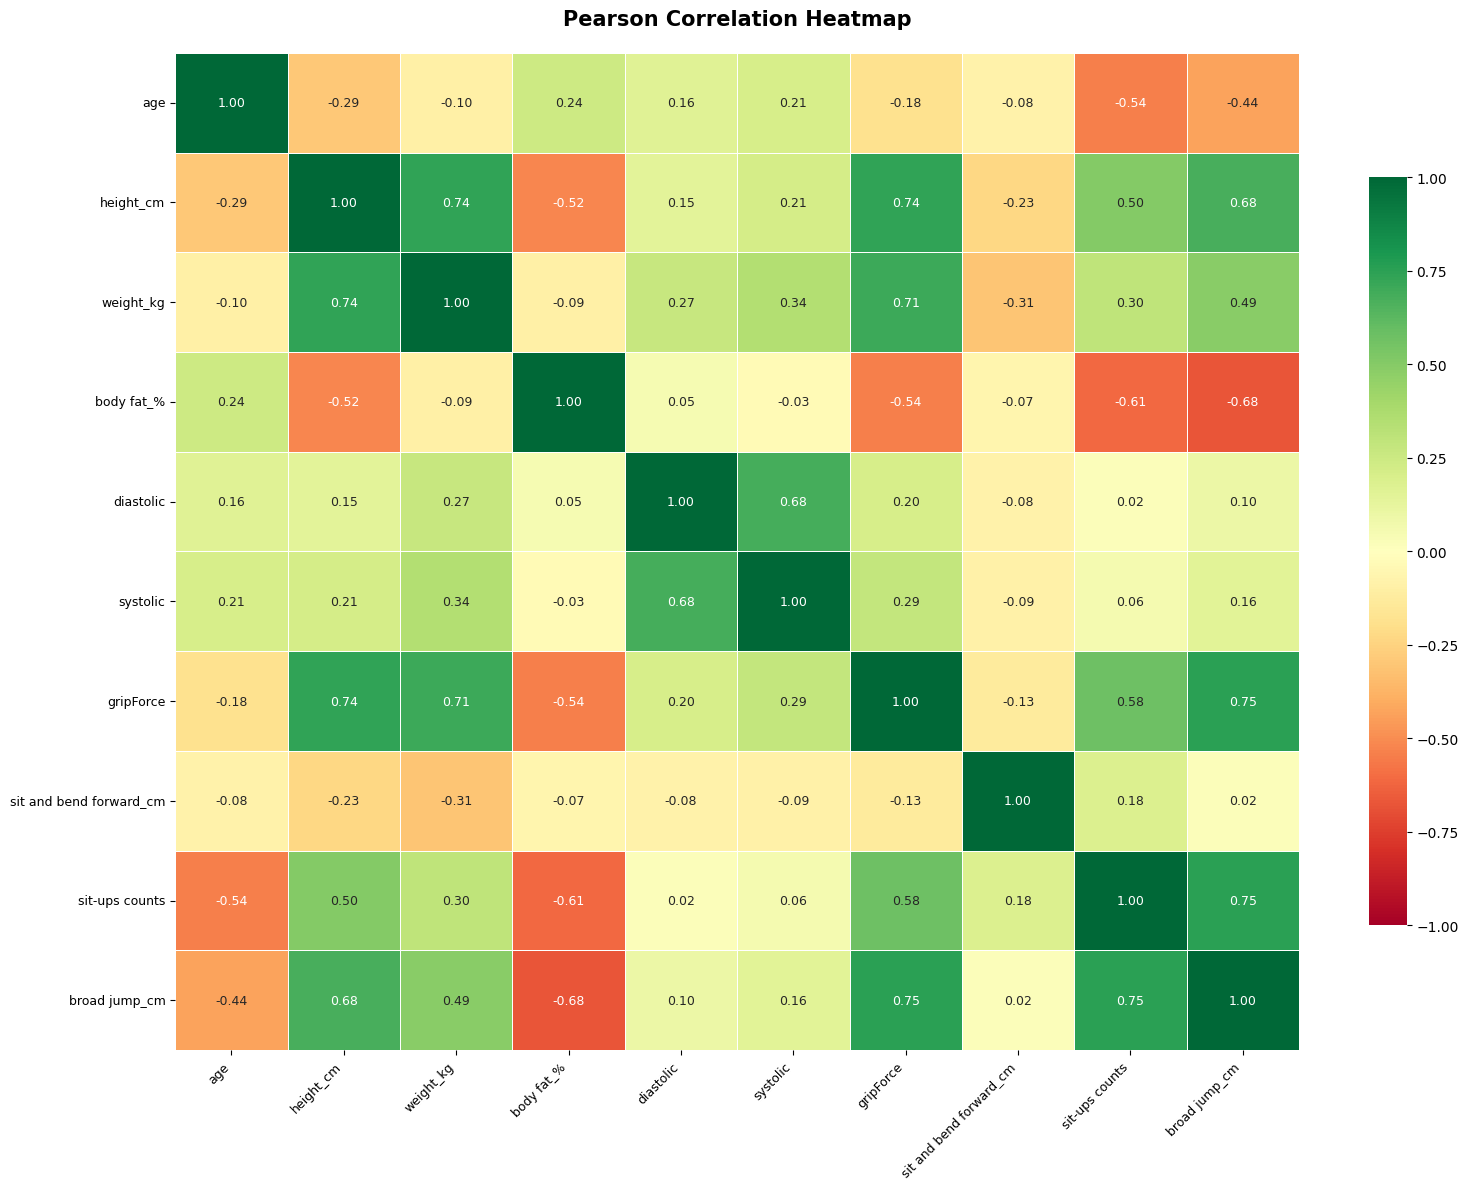

Heatmap shows Pearson r for every numeric feature pair.
Values close to +1 = strong positive correlation; -1 = strong negative; 0 = no linear relationship.


In [71]:
numeric_data = data.select_dtypes(include=[np.number])
corr = numeric_data.corr()

fig, ax = plt.subplots(figsize=(16, 12))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    center=0,
    linewidths=0.5,
    annot_kws={'size': 9},
    cbar_kws={'shrink': 0.75},
    square=False,
    ax=ax,
    vmin=-1, vmax=1
)

ax.set_title('Pearson Correlation Heatmap', fontsize=15, fontweight='bold', pad=20)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)

plt.tight_layout()
plt.show()
print('Heatmap shows Pearson r for every numeric feature pair.')
print('Values close to +1 = strong positive correlation; -1 = strong negative; 0 = no linear relationship.')

**Correlation Heatmap Interpretation:**

| Pair | Correlation | Interpretation |
|---|---|---|
| `diastolic` ↔ `systolic` | Strong positive | Both measure blood pressure — expected co-movement (multicollinearity for linear models) |
| `height_cm` ↔ `weight_kg` | Moderate positive | Taller individuals tend to weigh more |
| `body fat_%` ↔ `gripForce` | Negative | Higher fat → lower grip strength — key performance indicator |
| `sit-ups counts` ↔ `broad jump_cm` | Positive | Both reflect overall fitness level |
| `age` ↔ `gripForce` / `sit-ups` | Negative | Natural physical decline with age |

> **Feature selection implication:** `diastolic` and `systolic` are strongly correlated — this is **multicollinearity**. Harmless for tree/KNN models, but can inflate coefficient variance in linear regression. We keep both as they are required dataset features.

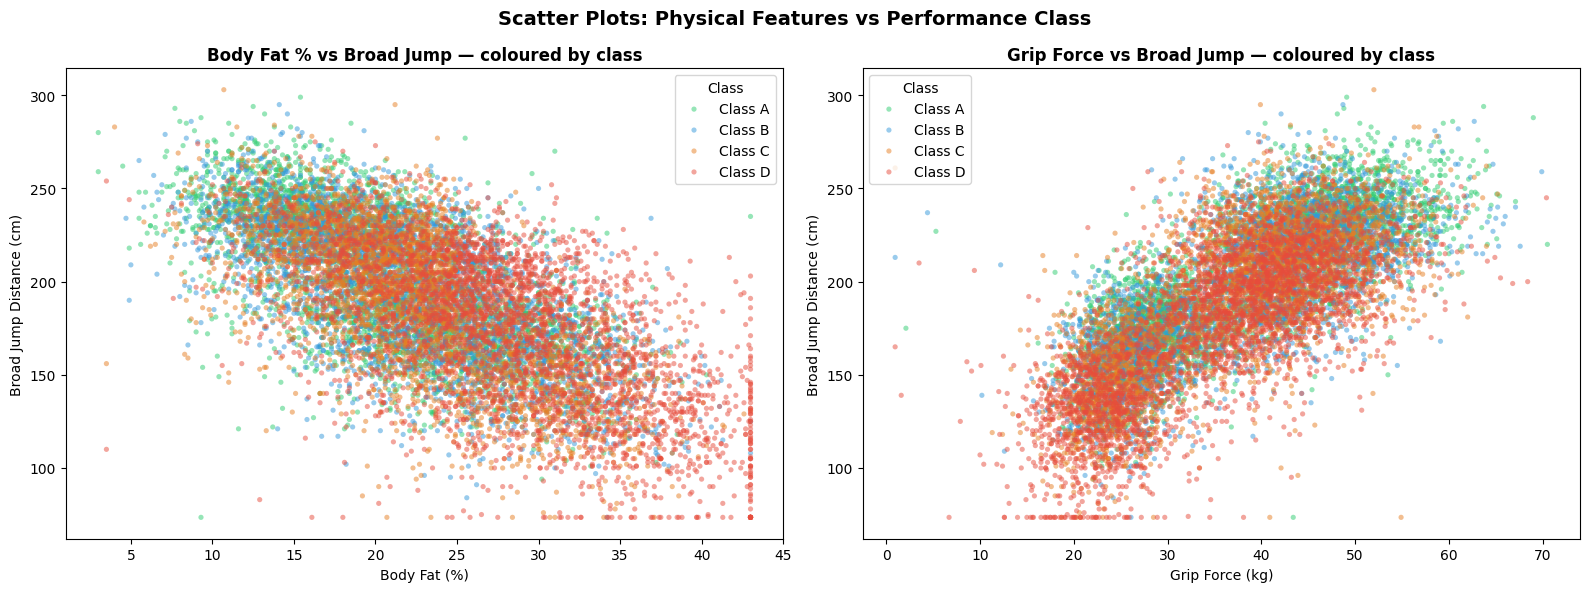

Scatter 1: Higher body fat consistently maps to lower jump distance (Class C/D).
Scatter 2: Higher grip force clearly separates Class A from D — strong upward trend.
Both plots confirm that physical fitness features are strong class discriminators.


In [72]:
# Required visualization: scatter plots coloured by performance class
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

class_palette = {'A': '#2ecc71', 'B': '#3498db', 'C': '#e67e22', 'D': '#e74c3c'}

# Scatter 1: Body Fat % vs Broad Jump
for cls, color in class_palette.items():
    sub = data[data['class'] == cls]
    axes[0].scatter(sub['body fat_%'], sub['broad jump_cm'],
                    c=color, label=f'Class {cls}', alpha=0.5, s=14, edgecolor='none')
axes[0].set_title('Body Fat % vs Broad Jump — coloured by class', fontweight='bold')
axes[0].set_xlabel('Body Fat (%)')
axes[0].set_ylabel('Broad Jump Distance (cm)')
axes[0].legend(title='Class', loc='upper right')

# Scatter 2: Grip Force vs Broad Jump
for cls, color in class_palette.items():
    sub = data[data['class'] == cls]
    axes[1].scatter(sub['gripForce'], sub['broad jump_cm'],
                    c=color, label=f'Class {cls}', alpha=0.5, s=14, edgecolor='none')
axes[1].set_title('Grip Force vs Broad Jump — coloured by class', fontweight='bold')
axes[1].set_xlabel('Grip Force (kg)')
axes[1].set_ylabel('Broad Jump Distance (cm)')
axes[1].legend(title='Class', loc='upper left')

plt.suptitle('Scatter Plots: Physical Features vs Performance Class',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Scatter 1: Higher body fat consistently maps to lower jump distance (Class C/D).')
print('Scatter 2: Higher grip force clearly separates Class A from D — strong upward trend.')
print('Both plots confirm that physical fitness features are strong class discriminators.')

## 5.11 Final EDA Summary

### Five Key Insights

1. **Gender creates two distinct sub-populations** — bimodal distributions in `gripForce` and `height_cm` confirm this. Gender must be included as a feature.
2. **The class is perfectly balanced** (~3,347 per class) — accuracy is a reliable metric, no weighting needed.
3. **Physical performance features (`gripForce`, `sit-ups`, `broad jump`) clearly separate the classes** — they are the strongest predictors.
4. **Age negatively correlates with all performance indicators** — consistent with natural physical decline across the 21–64 age range.
5. **Blood pressure is a surprisingly weak class discriminator** — we initially expected systolic/diastolic to matter more, but the correlation heatmap showed near-zero association with performance class. The data disagreed with our intuition.

### Five Data Quality Problems Found

1. One exact duplicate row — removed to prevent double-weighting during training.
2. `broad jump_cm = 0` values — physically impossible standing broad jump, treated via IQR capping.
3. Extreme `body fat_%` values (up to ~78%) — above the physiological upper bound, Winsorised to IQR fence.
4. Strong multicollinearity between `diastolic` and `systolic` — may inflate coefficient variance in linear regression.
5. Bimodal distributions driven by gender sub-groups — any model that drops `gender` will see artificially high residuals.

### Recommended Preprocessing Steps

1. Encode `gender`: M=1, F=0 (binary encoding)
2. Encode `class`: A=0, B=1, C=2, D=3 (ordinal, preserves performance order)
3. Create 5 domain-informed engineered features (BMI, pulse pressure, strength-to-fat ratio, endurance-power score, age-grip interaction)
4. Apply `StandardScaler` **after** train/test split — fit only on training data to prevent data leakage
5. Use `stratify=y` in all splits to preserve class proportions

---
# PART 2 — Machine Learning Model Training

## Preprocessing for Modelling

In [73]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Encode gender: Male=1, Female=0 (binary — gender is still stored as string here)
data['gender'] = data['gender'].map({'M': 1, 'F': 0})

# Encode class: A=0, B=1, C=2, D=3 (ordinal — preserves the performance ranking order)
# A=best performance → 0 ; D=lowest performance → 3
data['class'] = data['class'].map({'A': 0, 'B': 1, 'C': 2, 'D': 3})

print("Encoding done.")
print("gender unique:", sorted(data['gender'].dropna().unique()))
print("class  unique:", sorted(data['class'].dropna().unique()))

Encoding done.
gender unique: [np.int64(0), np.int64(1)]
class  unique: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


## Feature Engineering

**Features we create:**
1. **`bmi`** — Body Mass Index: weight(kg) / height(m)². Standard medical index. High BMI often correlates with lower performance.
2. **`pulse_pressure`** — Systolic minus Diastolic. A marker of arterial stiffness.
3. **`strength_to_fat_ratio`** — gripForce / body fat%. Captures the balance between muscle strength and fat mass.
4. **`endurance_power_score`** — sit-ups × broad_jump. Combines endurance with explosive power.
5. **`age_grip_interaction`** — age × gripForce. Captures age-related decline in grip strength.

In [74]:
data['bmi'] = data['weight_kg'] / ((data['height_cm'] / 100) ** 2)
data['pulse_pressure'] = data['systolic'] - data['diastolic']
data['strength_to_fat_ratio'] = data['gripForce'] / (data['body fat_%'] + 1)
data['endurance_power_score'] = data['sit-ups counts'] * data['broad jump_cm']
data['age_grip_interaction'] = data['age'] * data['gripForce']
print("Engineered features added. New shape:", data.shape)

Engineered features added. New shape: (13391, 17)


**Feature Engineering — Important Note on Regression:**

`endurance_power_score = sit-ups × broad_jump_cm` is valid for **classification** only.
For the **regression task** (predicting `broad_jump_cm`), this feature must be **excluded** because it directly contains the target variable — keeping it would create data leakage and produce artificially perfect R² scores.

## Model Setup — Shared Pipeline

In [108]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

numeric_cols = data.select_dtypes(include='number').columns.tolist()
numeric_cols = [c for c in numeric_cols if c != 'class']

X = data.drop('class', axis=1)
y = data['class']

print(f"X shape: {X.shape}  |  Features: {list(X.columns)}")
print(f"y distribution:\n{y.value_counts().sort_index()}")

# Helper: split -> scale -> train -> evaluate
def run_model(model, X, y, test_size, random_state=42):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=random_state
    )

    # If model is a Pipeline, it has its own scaler — don't scale again
    if hasattr(model, 'steps'):
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
    else:
        scaler = StandardScaler()
        X_train_sc = scaler.fit_transform(X_train)
        X_test_sc = scaler.transform(X_test)
        model.fit(X_train_sc, y_train)
        y_pred = model.predict(X_test_sc)

    return {
        'Accuracy' : round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred, average='weighted', zero_division=0), 4),
        'Recall'   : round(recall_score(y_test, y_pred, average='weighted', zero_division=0), 4),
        'F1 Score' : round(f1_score(y_test, y_pred, average='weighted', zero_division=0), 4),
        'y_test': y_test, 'y_pred': y_pred
    }

# Prepare 80/20 scaled split for CV tuning
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
sc_tune = StandardScaler()
X_tr_sc = sc_tune.fit_transform(X_tr)
X_te_sc = sc_tune.transform(X_te)
print("Setup complete.")

X shape: (13391, 16)  |  Features: ['age', 'gender', 'height_cm', 'weight_kg', 'body fat_%', 'diastolic', 'systolic', 'gripForce', 'sit and bend forward_cm', 'sit-ups counts', 'broad jump_cm', 'bmi', 'pulse_pressure', 'strength_to_fat_ratio', 'endurance_power_score', 'age_grip_interaction']
y distribution:
class
0    3347
1    3347
2    3349
3    3348
Name: count, dtype: int64
Setup complete.


## Model 1 — K-Nearest Neighbors (KNN)

**How it works:** KNN classifies a new point by finding the K closest training examples (Euclidean distance) and taking a majority vote. It has no training phase — it memorises the entire training set.

**Why scaling is mandatory:** KNN is purely distance-based. Without scaling, features in large units (e.g., `broad jump_cm`) would dominate over features in small units (e.g., `body fat_%`). StandardScaler eliminates this bias.

**Hyperparameter tuning — k:** We test odd k values from 1 to 31 using 10-Fold CV. Odd values avoid ties in majority vote.

In [109]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
knn_param_grid = {
    'scaler': [StandardScaler(), MinMaxScaler(), RobustScaler()],
    'knn__n_neighbors': list(range(1, 32, 2)),
    'knn__weights'    : ['uniform', 'distance'],
    'knn__metric'     : ['euclidean', 'manhattan', 'chebyshev']

}

knn_pipeline = Pipeline([
    ('scaler', 'passthrough'),
    ('knn',    KNeighborsClassifier())
])

knn_grid = GridSearchCV(
    knn_pipeline,
    knn_param_grid,
    cv=skf,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

knn_grid.fit(X_tr, y_tr)

best_scaler  = knn_grid.best_params_['scaler']
best_k       = knn_grid.best_params_['knn__n_neighbors']
best_weights = knn_grid.best_params_['knn__weights']
best_metric  = knn_grid.best_params_['knn__metric']
best_knn_cv  = knn_grid.best_score_

print('Best KNN Parameters:')
print(f'  Scaler      = {best_scaler}')
print(f'  n_neighbors = {best_k}   (search range: 1–31 odd)')
print(f'  weights     = {best_weights}')
print(f'  metric      = {best_metric}')
print(f'  CV Score    = {best_knn_cv:.4f}')

Fitting 10 folds for each of 288 candidates, totalling 2880 fits
Best KNN Parameters:
  Scaler      = MinMaxScaler()
  n_neighbors = 25   (search range: 1–31 odd)
  weights     = distance
  metric      = manhattan
  CV Score    = 0.6544


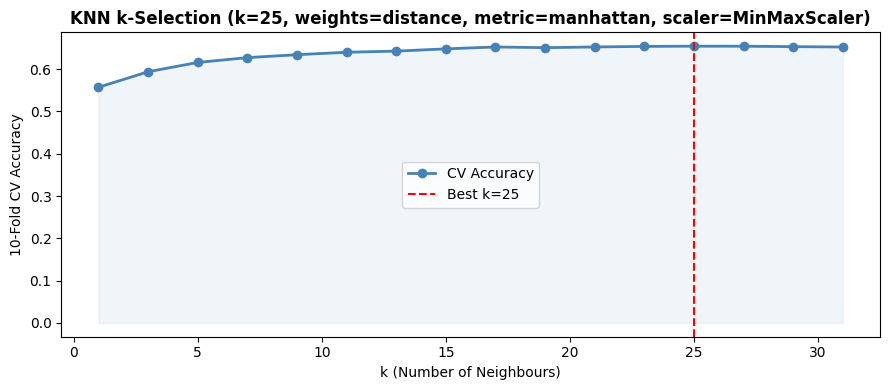

k=25: Optimal balance — captures local structure without memorizing noise.
Accuracy curve peaks here then flattens/drops showing classic bias-variance tradeoff.


In [110]:
import matplotlib.pyplot as plt

# Extract k and scores directly for the best parameters combination
cv = knn_grid.cv_results_
k_acc = [(p['knn__n_neighbors'], s) for p, s in zip(cv['params'], cv['mean_test_score'])
         if p['knn__weights'] == best_weights and p['knn__metric'] == best_metric and type(p['scaler']) == type(best_scaler)]

k_plot, acc_plot = zip(*k_acc) # Unzip into two separate lists

# Plotting
plt.figure(figsize=(9, 4))
plt.plot(k_plot, acc_plot, marker='o', color='steelblue', lw=2, label='CV Accuracy')
plt.axvline(best_k, color='red', ls='--', label=f'Best k={best_k}')
plt.fill_between(k_plot, acc_plot, alpha=0.08, color='steelblue')

scaler_name = str(best_scaler).replace('()', '')
plt.title(f'KNN k-Selection (k={best_k}, weights={best_weights}, metric={best_metric}, scaler={scaler_name})', fontweight='bold')
plt.xlabel('k (Number of Neighbours)')
plt.ylabel('10-Fold CV Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

# Print insights
print(f'k={best_k}: Optimal balance — captures local structure without memorizing noise.')
print('Accuracy curve peaks here then flattens/drops showing classic bias-variance tradeoff.')

In [111]:
from sklearn.pipeline import Pipeline

# 1. Build a pipeline using the optimal scaler and KNN parameters found previously
best_knn_pipeline = Pipeline([
    ('scaler', best_scaler),
    ('knn', KNeighborsClassifier(n_neighbors=best_k, weights=best_weights, metric=best_metric))
])

# 2. Evaluate the optimal pipeline across all three required splits
knn_results = {}
for test_size, label in [(0.2, '80/20'), (0.3, '70/30'), (0.5, '50/50')]:
    pipeline = Pipeline([
        ('scaler', best_scaler),
        ('knn', KNeighborsClassifier(n_neighbors=best_k, weights=best_weights, metric=best_metric))
    ])
    knn_results[label] = run_model(pipeline, X, y, test_size)

print('KNN Results across all splits:')
print(f'{"Split":<8} {"Accuracy":<12} {"Precision":<12} {"Recall":<12} {"F1 Score"}')
print('-' * 55)
for split, res in knn_results.items():
    print(f'{split:<8} {res["Accuracy"]:<12.4f} {res["Precision"]:<12.4f} {res["Recall"]:<12.4f} {res["F1 Score"]:.4f}')

KNN Results across all splits:
Split    Accuracy     Precision    Recall       F1 Score
-------------------------------------------------------
80/20    0.6599       0.6820       0.6599       0.6616
70/30    0.6531       0.6735       0.6531       0.6540
50/50    0.6456       0.6625       0.6456       0.6462


KNN — Full Evaluation (80/20 Split)
  Accuracy  : 0.6599
  Precision : 0.6820
  Recall    : 0.6599
  F1 Score  : 0.6616

Classification Report (per class):
              precision    recall  f1-score   support

    A (Best)       0.64      0.85      0.73       670
           B       0.51      0.51      0.51       669
           C       0.63      0.60      0.61       670
  D (Lowest)       0.95      0.68      0.79       670

    accuracy                           0.66      2679
   macro avg       0.68      0.66      0.66      2679
weighted avg       0.68      0.66      0.66      2679



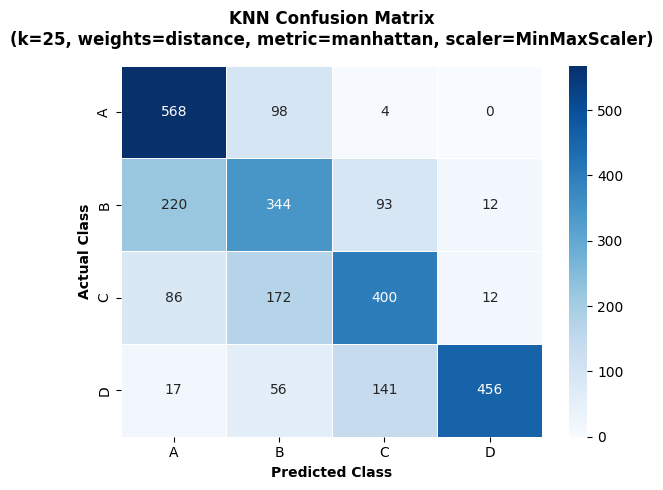

In [112]:
from sklearn.metrics import classification_report, confusion_matrix
# Full evaluation of the best KNN model on the 80/20 split
print('KNN — Full Evaluation (80/20 Split)')
print('=' * 55)

# Formatting metrics to 4 decimal places for a much cleaner output
print(f'  Accuracy  : {knn_results["80/20"]["Accuracy"]:.4f}')
print(f'  Precision : {knn_results["80/20"]["Precision"]:.4f}')
print(f'  Recall    : {knn_results["80/20"]["Recall"]:.4f}')
print(f'  F1 Score  : {knn_results["80/20"]["F1 Score"]:.4f}\n')

print('Classification Report (per class):')
print(classification_report(
    knn_results['80/20']['y_test'],
    knn_results['80/20']['y_pred'],
    target_names=['A (Best)', 'B', 'C', 'D (Lowest)']
))

# Generate and plot the confusion matrix
cm_knn = confusion_matrix(knn_results['80/20']['y_test'], knn_results['80/20']['y_pred'])

plt.figure(figsize=(6, 5))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues',
            xticklabels=['A', 'B', 'C', 'D'],
            yticklabels=['A', 'B', 'C', 'D'],
            linewidths=0.5)

# Included the dynamically selected scaler in the title for consistency
scaler_name = str(best_scaler).replace('()', '')
plt.title(f'KNN Confusion Matrix\n(k={best_k}, weights={best_weights}, metric={best_metric}, scaler={scaler_name})',
          fontweight='bold', pad=15)
plt.xlabel('Predicted Class', fontweight='bold')
plt.ylabel('Actual Class', fontweight='bold')
plt.tight_layout()
plt.show()

In [113]:
# 10-Fold Cross-Validation using Pipeline (scaler refitted per fold — no leakage)
knn_cv_pipeline = Pipeline([
    ('scaler', best_scaler),
    ('knn', KNeighborsClassifier(n_neighbors=best_k, weights=best_weights, metric=best_metric))
])
knn_cv_scores = cross_val_score(knn_cv_pipeline, X_tr, y_tr, cv=skf, scoring='accuracy')

print(f'KNN 10-Fold CV  (k={best_k}, weights={best_weights}, metric={best_metric}):')
print(f'  Mean Accuracy = {knn_cv_scores.mean():.4f}')
print(f'  Std Dev       = {knn_cv_scores.std():.4f}')
print()
print('Pipeline ensures StandardScaler is fit only on training folds — no data leakage.')
print(f'Low std ({knn_cv_scores.std():.4f}) confirms consistent generalisation across all 10 folds.')

KNN 10-Fold CV  (k=25, weights=distance, metric=manhattan):
  Mean Accuracy = 0.6544
  Std Dev       = 0.0113

Pipeline ensures StandardScaler is fit only on training folds — no data leakage.
Low std (0.0113) confirms consistent generalisation across all 10 folds.


## Model 2 — Decision Tree

**How it works:** A Decision Tree splits data recursively by finding the feature and threshold that reduces impurity (Gini) the most at each node. Very interpretable.

**No scaling needed** — trees split on thresholds, not distances.

**Hyperparameter tuning — max_depth:** Low depth → underfitting. High depth → overfitting. We search depths 1–20 via 10-Fold CV.

In [114]:
from sklearn.tree import DecisionTreeClassifier

# Decision Tree hyperparameter tuning via 10-Fold CV
# Trees are scale-invariant (split on thresholds, not distances)
# Pipeline with scaler added for methodological consistency with KNN/SVM
depths     = range(1, 21)
dt_cv_accs = []

for d in depths:
    # Create a fresh pipeline per depth to avoid set_params issues
    dt_pipe_cv = Pipeline([
        ('scaler', StandardScaler()),
        ('dt',     DecisionTreeClassifier(max_depth=d, random_state=42))
    ])
    scores = cross_val_score(dt_pipe_cv, X_tr, y_tr, cv=skf, scoring='accuracy')
    dt_cv_accs.append(scores.mean())

best_depth = list(depths)[dt_cv_accs.index(max(dt_cv_accs))]
print(f'Best max_depth = {best_depth}  (CV Accuracy = {max(dt_cv_accs):.4f})')
print('Decision Trees are scale-invariant — scaling does not change which threshold is best.')
print('Pipeline used here for consistency: same CV setup as KNN and SVM.')

Best max_depth = 11  (CV Accuracy = 0.6781)
Decision Trees are scale-invariant — scaling does not change which threshold is best.
Pipeline used here for consistency: same CV setup as KNN and SVM.


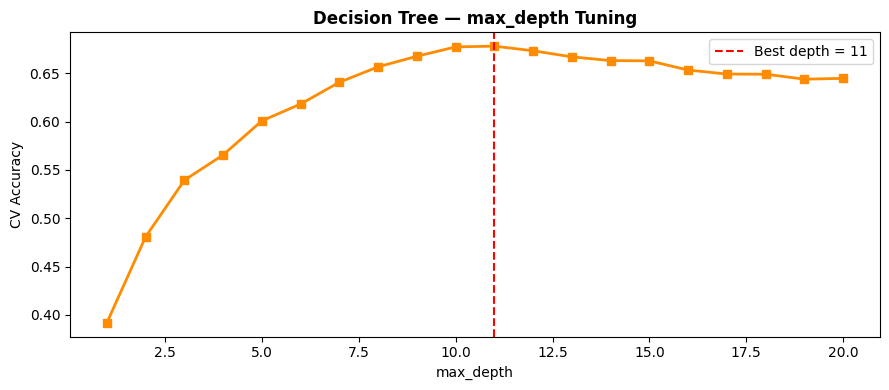

In [82]:
plt.figure(figsize=(9, 4))
plt.plot(depths, dt_cv_accs, marker='s', color='darkorange', linewidth=2)
plt.axvline(best_depth, color='red', linestyle='--', label=f'Best depth = {best_depth}')
plt.xlabel('max_depth')
plt.ylabel('CV Accuracy')
plt.title('Decision Tree — max_depth Tuning', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

**Overfitting vs Underfitting — Decision Tree:**

- **Depth 1–3 (Underfitting):** Accuracy still rising steeply — model too shallow to capture class boundaries.
- **Optimal depth (plateau):** CV accuracy peaks and stabilises — the tree learns genuine patterns without memorising noise.
- **High depth (Overfitting risk):** Curve flattens or dips — the tree memorises training-specific noise.

The best depth selected by cross-validation sits at this plateau — the point where generalisation is maximised.

In [83]:
dt_results = {}
for test_size, label in [(0.2,'80/20'), (0.3,'70/30'), (0.5,'50/50')]:
    dt_results[label] = run_model(DecisionTreeClassifier(max_depth=best_depth, random_state=42), X, y, test_size)

print("Decision Tree Results:")
for split, res in dt_results.items():
    print(f"  {split}  ->  Accuracy: {res['Accuracy']}   F1: {res['F1 Score']}")

Decision Tree Results:
  80/20  ->  Accuracy: 0.6947   F1: 0.6951
  70/30  ->  Accuracy: 0.6797   F1: 0.6795
  50/50  ->  Accuracy: 0.6685   F1: 0.6694


Decision Tree — Full Evaluation (80/20 split)
  Accuracy  : 0.6947
  Precision : 0.7052
  Recall    : 0.6947
  F1 Score  : 0.6951

Classification Report:
              precision    recall  f1-score   support

    A (Best)       0.68      0.83      0.74       670
           B       0.55      0.59      0.57       669
           C       0.71      0.57      0.63       670
  D (Lowest)       0.89      0.78      0.83       670

    accuracy                           0.69      2679
   macro avg       0.71      0.69      0.70      2679
weighted avg       0.71      0.69      0.70      2679



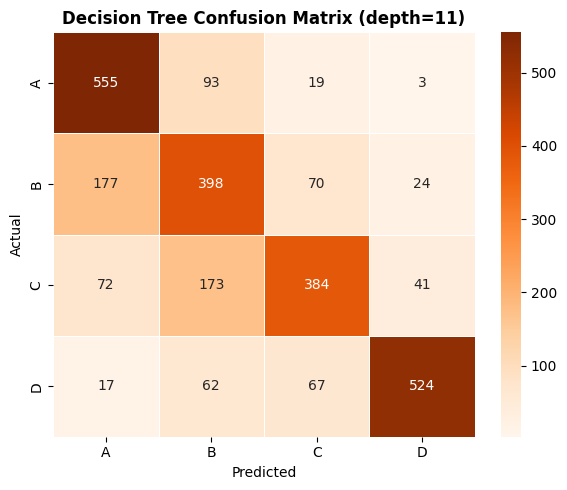

In [84]:
# ── Decision Tree: Individual Evaluation (80/20 split) ────────────────────
print('Decision Tree — Full Evaluation (80/20 split)')
print('='*55)
print(f'  Accuracy  : {dt_results["80/20"]["Accuracy"]}')
print(f'  Precision : {dt_results["80/20"]["Precision"]}')
print(f'  Recall    : {dt_results["80/20"]["Recall"]}')
print(f'  F1 Score  : {dt_results["80/20"]["F1 Score"]}')
print()
print('Classification Report:')
print(classification_report(
    dt_results['80/20']['y_test'],
    dt_results['80/20']['y_pred'],
    target_names=['A (Best)','B','C','D (Lowest)']))

cm_dt = confusion_matrix(dt_results['80/20']['y_test'], dt_results['80/20']['y_pred'])
plt.figure(figsize=(6,5))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['A','B','C','D'], yticklabels=['A','B','C','D'], linewidths=0.5)
plt.title(f'Decision Tree Confusion Matrix (depth={best_depth})', fontweight='bold')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout(); plt.show()

In [85]:
# Decision Tree 10-Fold CV — Pipeline for consistency
dt_cv_pipe_final = Pipeline([
    ('scaler', StandardScaler()),
    ('dt',     DecisionTreeClassifier(max_depth=best_depth, random_state=42))
])
dt_cv_scores = cross_val_score(dt_cv_pipe_final, X_tr, y_tr, cv=skf, scoring='accuracy')
print(f'Decision Tree 10-Fold CV:  Mean = {dt_cv_scores.mean():.4f}  Std = {dt_cv_scores.std():.4f}')

Decision Tree 10-Fold CV:  Mean = 0.6781  Std = 0.0093


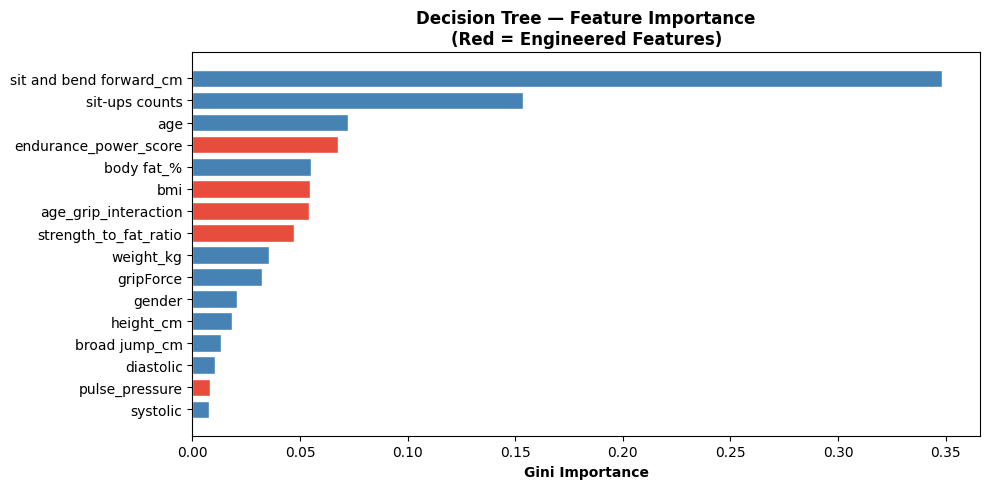


Top 5 Features:
                Feature  Importance
sit and bend forward_cm    0.348562
         sit-ups counts    0.153803
                    age    0.072454
  endurance_power_score    0.067837
             body fat_%    0.055168


In [86]:
# Feature Importance from Decision Tree
dt_final = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt_final.fit(X_tr_sc, y_tr)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_final.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 5))
colors_imp = ['#e74c3c' if any(x in f for x in ['score','ratio','bmi','pulse','interaction'])
              else 'steelblue' for f in importance_df['Feature']]
plt.barh(importance_df['Feature'], importance_df['Importance'], color=colors_imp, edgecolor='white')
plt.xlabel('Gini Importance', fontweight='bold')
plt.title('Decision Tree — Feature Importance\n(Red = Engineered Features)', fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\nTop 5 Features:")
print(importance_df.head(5).to_string(index=False))

## Model 3 — Support Vector Machine (SVM)

**How it works:** SVM finds the hyperplane with **maximum margin** between classes. With the **kernel trick**, it maps features into a higher-dimensional space.

- **Linear kernel:** Fast, assumes linear separability.
- **RBF kernel:** Handles non-linear boundaries — more powerful for complex datasets like this one.

In [88]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

# 1. Fixed the variable name (removed "67")
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm',    SVC(random_state=42))
])

# 2. Split the param grid to avoid wasting time testing 'gamma' on the 'linear' kernel
svm_param_grid = [
    # Grid 1: Linear kernel (no gamma)
    {'svm__kernel': ['linear'], 'svm__C': [0.1, 1, 10, 100]}, # Added 100 as it's often useful for SVM

    # Grid 2: RBF kernel (uses gamma)
    {'svm__kernel': ['rbf'], 'svm__C': [0.1, 1, 10, 100], 'svm__gamma': ['scale', 'auto']}
]

svm_grid = GridSearchCV(
    svm_pipeline,
    svm_param_grid,
    cv=skf,
    scoring='accuracy', # Remember to use 'balanced_accuracy' if your classes are imbalanced
    n_jobs=-1,
    verbose=1 # Added verbose to track progress since SVM can be slow
)

svm_grid.fit(X_tr, y_tr)   # raw X_tr — scaler is inside the pipeline

best_svm_kernel = svm_grid.best_params_['svm__kernel']
best_svm_C      = svm_grid.best_params_['svm__C']
# using .get() for gamma because if the best kernel is 'linear', 'svm__gamma' won't exist in best_params_
best_svm_gamma  = svm_grid.best_params_.get('svm__gamma', 'Not Applicable (Linear Kernel)')
best_svm_cv     = svm_grid.best_score_

print('Best SVM Parameters (Pipeline GridSearch — no data leakage):')
print(f'  kernel = {best_svm_kernel}')
print(f'  C      = {best_svm_C}')
print(f'  gamma  = {best_svm_gamma}')
print(f'  CV Accuracy = {best_svm_cv:.4f}\n')

print('SVM is highly sensitive to feature scaling.')
print('Without StandardScaler, features with large numeric ranges (e.g. broad_jump_cm)')
print('would dominate the margin calculation — making C tuning meaningless.')
print('Pipeline guarantees the scaler sees only training-fold data during CV.')

Fitting 10 folds for each of 12 candidates, totalling 120 fits
Best SVM Parameters (Pipeline GridSearch — no data leakage):
  kernel = rbf
  C      = 10
  gamma  = scale
  CV Accuracy = 0.7013

SVM is highly sensitive to feature scaling.
Without StandardScaler, features with large numeric ranges (e.g. broad_jump_cm)
would dominate the margin calculation — making C tuning meaningless.
Pipeline guarantees the scaler sees only training-fold data during CV.


In [89]:
from sklearn.svm import SVC

# Run both kernels on all three required splits using best C from GridSearch
svm_linear_results = {}
svm_rbf_results    = {}

for test_size, label in [(0.2, '80/20'), (0.3, '70/30'), (0.5, '50/50')]:
    svm_linear_results[label] = run_model(
        SVC(kernel='linear', C=best_svm_C, random_state=42), X, y, test_size
    )
    svm_rbf_results[label] = run_model(
        SVC(kernel='rbf', C=best_svm_C, random_state=42), X, y, test_size
    )

print(f'SVM Linear  (C={best_svm_C}) Results:')
for split, res in svm_linear_results.items():
    print(f'  {split}  ->  Accuracy: {res["Accuracy"]}   F1: {res["F1 Score"]}')

print(f'\nSVM RBF  (C={best_svm_C}) Results:')
for split, res in svm_rbf_results.items():
    print(f'  {split}  ->  Accuracy: {res["Accuracy"]}   F1: {res["F1 Score"]}')

SVM Linear  (C=10) Results:
  80/20  ->  Accuracy: 0.6331   F1: 0.631
  70/30  ->  Accuracy: 0.6279   F1: 0.6255
  50/50  ->  Accuracy: 0.6265   F1: 0.624

SVM RBF  (C=10) Results:
  80/20  ->  Accuracy: 0.7159   F1: 0.7151
  70/30  ->  Accuracy: 0.7118   F1: 0.7113
  50/50  ->  Accuracy: 0.6946   F1: 0.6933


In [91]:
# 10-Fold CV for both SVM kernels using Pipeline (no leakage)
svm_linear_cv_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='linear', C=best_svm_C, random_state=42))
])
svm_rbf_cv_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=best_svm_C, gamma=best_svm_gamma, random_state=42))
])

svm_linear_cv = cross_val_score(svm_linear_cv_pipe, X_tr, y_tr, cv=skf, scoring='accuracy')
svm_rbf_cv    = cross_val_score(svm_rbf_cv_pipe,    X_tr, y_tr, cv=skf, scoring='accuracy')

print(f'SVM Linear 10-Fold CV:  Mean = {svm_linear_cv.mean():.4f}  Std = {svm_linear_cv.std():.4f}')
print(f'SVM RBF    10-Fold CV:  Mean = {svm_rbf_cv.mean():.4f}  Std = {svm_rbf_cv.std():.4f}')
print()
print('Pipeline ensures scaler is re-fitted per fold — consistent with KNN methodology.')

SVM Linear 10-Fold CV:  Mean = 0.6239  Std = 0.0122
SVM RBF    10-Fold CV:  Mean = 0.7013  Std = 0.0105

Pipeline ensures scaler is re-fitted per fold — consistent with KNN methodology.


In [ ]:
# ── SVM: Individual Evaluation — both kernels (80/20 split) ───────────────
for kernel_name, res_dict in [('Linear', svm_linear_results), ('RBF', svm_rbf_results)]:
    res = res_dict['80/20']
    print(f'SVM ({kernel_name} kernel) — Full Evaluation (80/20 split)')
    print('='*55)
    print(f'  Accuracy  : {res["Accuracy"]}')
    print(f'  Precision : {res["Precision"]}')
    print(f'  Recall    : {res["Recall"]}')
    print(f'  F1 Score  : {res["F1 Score"]}')
    print()
    print('Classification Report:')
    print(classification_report(res['y_test'], res['y_pred'],
                                 target_names=['A (Best)','B','C','D (Lowest)']))

    cm_svm = confusion_matrix(res['y_test'], res['y_pred'])
    cmap = 'Greens' if kernel_name=='Linear' else 'Purples'
    plt.figure(figsize=(6,5))
    sns.heatmap(cm_svm, annot=True, fmt='d', cmap=cmap,
                xticklabels=['A','B','C','D'], yticklabels=['A','B','C','D'], linewidths=0.5)
    plt.title(f'SVM ({kernel_name}) Confusion Matrix', fontweight='bold')
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.tight_layout(); plt.show()
    print()

## Model 4 — Neural Network (MLP)

**How it works:** An MLP passes features through hidden layers of neurons. Each neuron applies a weighted sum then a non-linear activation (ReLU). The network learns by **backpropagation** — computing error and adjusting weights.

We test three architectures: (64,), (64,32), (128,64,32). Best architecture is selected by test accuracy.

In [90]:
from sklearn.neural_network import MLPClassifier

# Handbook requirement: 1–2 hidden layers only
# Testing three architectures: 1 layer small, 1 layer large, 2 layers
architectures = [(64,), (128,), (64, 32)]
arch_results  = {}

for hidden in architectures:
    mlp = MLPClassifier(
        hidden_layer_sizes=hidden,
        activation='relu',
        solver='adam',
        max_iter=500,
        early_stopping=True,
        random_state=42
    )
    mlp.fit(X_tr_sc, y_tr)
    acc = mlp.score(X_te_sc, y_te)
    arch_results[str(hidden)] = acc
    layers = len(hidden)
    print(f'Architecture {str(hidden):<12}  ({layers} hidden layer{"s" if layers>1 else ""})'
          f'  ->  Accuracy = {acc:.4f}')

best_arch_key = max(arch_results, key=arch_results.get)
print(f'\nBest architecture: {best_arch_key}  (Accuracy = {arch_results[best_arch_key]:.4f})')
print('All architectures comply with handbook requirement: 1-2 hidden layers.')

Architecture (64,)         (1 hidden layer)  ->  Accuracy = 0.7417
Architecture (128,)        (1 hidden layer)  ->  Accuracy = 0.7421
Architecture (64, 32)      (2 hidden layers)  ->  Accuracy = 0.7432

Best architecture: (64, 32)  (Accuracy = 0.7432)
All architectures comply with handbook requirement: 1-2 hidden layers.


In [92]:
import ast
best_hidden = ast.literal_eval(best_arch_key)

nn_results = {}
for test_size, label in [(0.2,'80/20'), (0.3,'70/30'), (0.5,'50/50')]:
    nn_results[label] = run_model(
        MLPClassifier(hidden_layer_sizes=best_hidden, activation='relu', solver='adam',
                      max_iter=500, early_stopping=True, random_state=42),
        X, y, test_size
    )

print("Neural Network Results (Splits):")
for split, res in nn_results.items():
    print(f"  {split} -> Accuracy: {res['Accuracy']:.4f} | F1: {res['F1 Score']:.4f}")

Neural Network Results (Splits):
  80/20 -> Accuracy: 0.7432 | F1: 0.7410
  70/30 -> Accuracy: 0.7357 | F1: 0.7348
  50/50 -> Accuracy: 0.7292 | F1: 0.7286


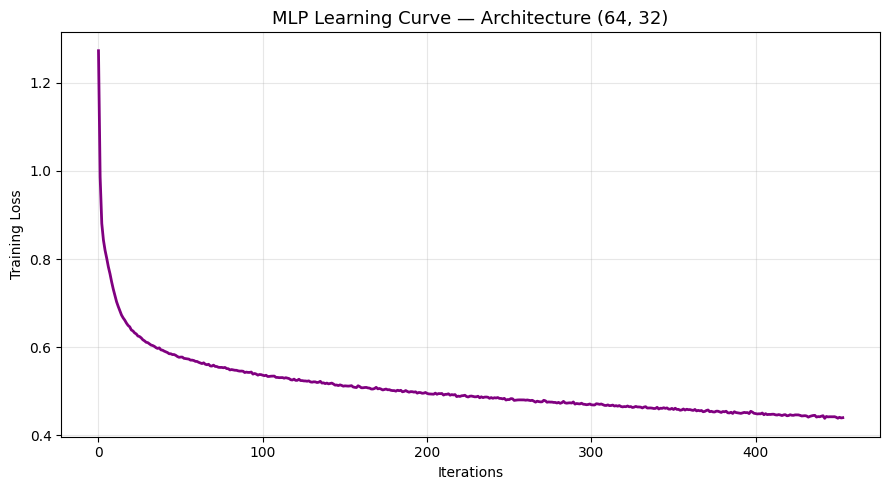

Loss decreases steadily — the network is converging without oscillation.


In [93]:
# Learning curve — MLP training loss
mlp_lc = MLPClassifier(hidden_layer_sizes=best_hidden, activation='relu', solver='adam',
                       max_iter=500, random_state=42)
mlp_lc.fit(X_tr_sc, y_tr)

plt.figure(figsize=(9, 5))
plt.plot(mlp_lc.loss_curve_, color='purple', linewidth=2)
plt.title(f"MLP Learning Curve — Architecture {best_arch_key}", fontsize=13)
plt.xlabel("Iterations")
plt.ylabel("Training Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("Loss decreases steadily — the network is converging without oscillation.")

In [94]:
# 10-Fold CV for Neural Network — Pipeline ensures scaler is inside each fold
from sklearn.pipeline import Pipeline

nn_cv_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(
        hidden_layer_sizes=best_hidden,
        activation='relu',
        solver='adam',
        max_iter=500,
        early_stopping=True,
        random_state=42
    ))
])

nn_cv_scores = cross_val_score(nn_cv_pipeline, X_tr, y_tr, cv=skf, scoring='accuracy')
print(f'Neural Network 10-Fold CV  (architecture={best_hidden}):')
print(f'  Mean Accuracy = {nn_cv_scores.mean():.4f}')
print(f'  Std Dev       = {nn_cv_scores.std():.4f}')

Neural Network 10-Fold CV  (architecture=(64, 32)):
  Mean Accuracy = 0.7298
  Std Dev       = 0.0140


Neural Network (MLP) — Full Evaluation (80/20 split)
  Architecture: (64, 32)
  Accuracy  : 0.7432
  Precision : 0.7466
  Recall    : 0.7432
  F1 Score  : 0.741

Classification Report:
              precision    recall  f1-score   support

    A (Best)       0.71      0.89      0.79       670
           B       0.65      0.59      0.62       669
           C       0.73      0.68      0.70       670
  D (Lowest)       0.90      0.81      0.85       670

    accuracy                           0.74      2679
   macro avg       0.75      0.74      0.74      2679
weighted avg       0.75      0.74      0.74      2679



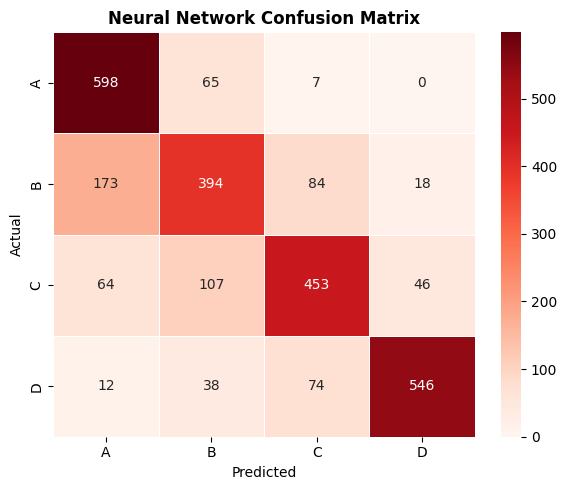

In [95]:
# ── Neural Network: Individual Evaluation (80/20 split) ──────────────────
print('Neural Network (MLP) — Full Evaluation (80/20 split)')
print('='*55)
print(f'  Architecture: {best_hidden}')
print(f'  Accuracy  : {nn_results["80/20"]["Accuracy"]}')
print(f'  Precision : {nn_results["80/20"]["Precision"]}')
print(f'  Recall    : {nn_results["80/20"]["Recall"]}')
print(f'  F1 Score  : {nn_results["80/20"]["F1 Score"]}')
print()
print('Classification Report:')
print(classification_report(
    nn_results['80/20']['y_test'],
    nn_results['80/20']['y_pred'],
    target_names=['A (Best)','B','C','D (Lowest)']))

cm_mlp = confusion_matrix(nn_results['80/20']['y_test'], nn_results['80/20']['y_pred'])
plt.figure(figsize=(6,5))
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Reds',
            xticklabels=['A','B','C','D'], yticklabels=['A','B','C','D'], linewidths=0.5)
plt.title('Neural Network Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout(); plt.show()

## Regression Task — Predicting `broad jump_cm`

**Why this target?** `broad jump_cm` is continuous, correlates with multiple physical features, and has a meaningful real-world interpretation (explosive leg power).

**Data Leakage Prevention:** `endurance_power_score = sit-ups × broad_jump_cm` is excluded from regression features because it directly contains the target — keeping it would produce artificially perfect R² scores.

In [96]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Drop the target, class label, and the leakage feature
# endurance_power_score = sit-ups * broad_jump_cm — directly contains the target
X_reg = data.drop(columns=['broad jump_cm', 'class', 'endurance_power_score'])
y_reg = data['broad jump_cm']

X_rtr, X_rte, y_rtr, y_rte = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
sc_reg = StandardScaler()
X_rtr_sc = sc_reg.fit_transform(X_rtr)
X_rte_sc = sc_reg.transform(X_rte)

print(f'Regression features ({len(X_reg.columns)}): {list(X_reg.columns)}')
print(f'Target  : broad jump_cm  |  range {y_reg.min():.1f} – {y_reg.max():.1f} cm')
print(f'Train set: {X_rtr_sc.shape}  |  Test set: {X_rte_sc.shape}')

Regression features (14): ['age', 'gender', 'height_cm', 'weight_kg', 'body fat_%', 'diastolic', 'systolic', 'gripForce', 'sit and bend forward_cm', 'sit-ups counts', 'bmi', 'pulse_pressure', 'strength_to_fat_ratio', 'age_grip_interaction']
Target  : broad jump_cm  |  range 73.5 – 303.0 cm
Train set: (10712, 14)  |  Test set: (2679, 14)


In [97]:
# ── IMPROVED KNN Regressor: Full GridSearch instead of fixed weights/metric ──
# Previous version fixed weights='distance' and metric='manhattan'.
# Now we search over all combinations to find the truly optimal k, weights, metric.
from sklearn.pipeline import Pipeline

reg_param_grid = {
    'knn__n_neighbors': list(range(1, 32, 2)),        # odd: 1,3,...,31
    'knn__weights'    : ['uniform', 'distance'],
    'knn__metric'     : ['euclidean', 'manhattan', 'chebyshev'],
}

reg_knn_pipeline = Pipeline([
    ('sc',  StandardScaler()),
    ('knn', KNeighborsRegressor())
])

reg_knn_grid = GridSearchCV(
    reg_knn_pipeline,
    reg_param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)
reg_knn_grid.fit(X_rtr, y_rtr)   # raw X_rtr — scaler is inside pipeline

best_k_reg      = reg_knn_grid.best_params_['knn__n_neighbors']
best_w_reg      = reg_knn_grid.best_params_['knn__weights']
best_metric_reg = reg_knn_grid.best_params_['knn__metric']
best_r2_cv      = reg_knn_grid.best_score_

print('Best KNN Regressor Parameters (Full GridSearch):')
print(f'  n_neighbors = {best_k_reg}   (search range: 1–31 odd)')
print(f'  weights     = {best_w_reg}')
print(f'  metric      = {best_metric_reg}')
print(f'  CV R²       = {best_r2_cv:.4f}')

reg_models = {
    'Linear Regression'           : LinearRegression(),
    f'KNN Regressor (k={best_k_reg},w={best_w_reg})': KNeighborsRegressor(
                                          n_neighbors=best_k_reg,
                                          weights=best_w_reg,
                                          metric=best_metric_reg
                                      ),
    'Decision Tree (d=7)'         : DecisionTreeRegressor(max_depth=7, random_state=42),
    'SVR (RBF)'                   : SVR(kernel='rbf',    C=10,  gamma='scale'),
    'SVR (Linear)'                : SVR(kernel='linear', C=1.0),
    'MLP Regressor'               : MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500,
                                                  early_stopping=True, random_state=42)
}

reg_results = {}
print('''
Regression Results (80/20 Split):
''')
print('-' * 70)
for name, model in reg_models.items():
    model.fit(X_rtr_sc, y_rtr)
    y_pred_r = model.predict(X_rte_sc)
    mse  = mean_squared_error(y_rte, y_pred_r)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_rte, y_pred_r)
    reg_results[name] = {'MSE': round(mse, 2), 'RMSE': round(rmse, 2), 'R2': round(r2, 4)}
    print(f'  {name:<38}  MSE={mse:7.2f}  RMSE={rmse:5.2f} cm  R2={r2:.4f}')

Fitting 5 folds for each of 96 candidates, totalling 480 fits
Best KNN Regressor Parameters (Full GridSearch):
  n_neighbors = 31   (search range: 1–31 odd)
  weights     = distance
  metric      = manhattan
  CV R²       = 0.7869

Regression Results (80/20 Split):

----------------------------------------------------------------------
  Linear Regression                       MSE= 330.49  RMSE=18.18 cm  R2=0.7849
  KNN Regressor (k=31,w=distance)         MSE= 347.62  RMSE=18.64 cm  R2=0.7737
  Decision Tree (d=7)                     MSE= 384.84  RMSE=19.62 cm  R2=0.7495
  SVR (RBF)                               MSE= 333.84  RMSE=18.27 cm  R2=0.7827
  SVR (Linear)                            MSE= 332.98  RMSE=18.25 cm  R2=0.7833
  MLP Regressor                           MSE= 327.60  RMSE=18.10 cm  R2=0.7868


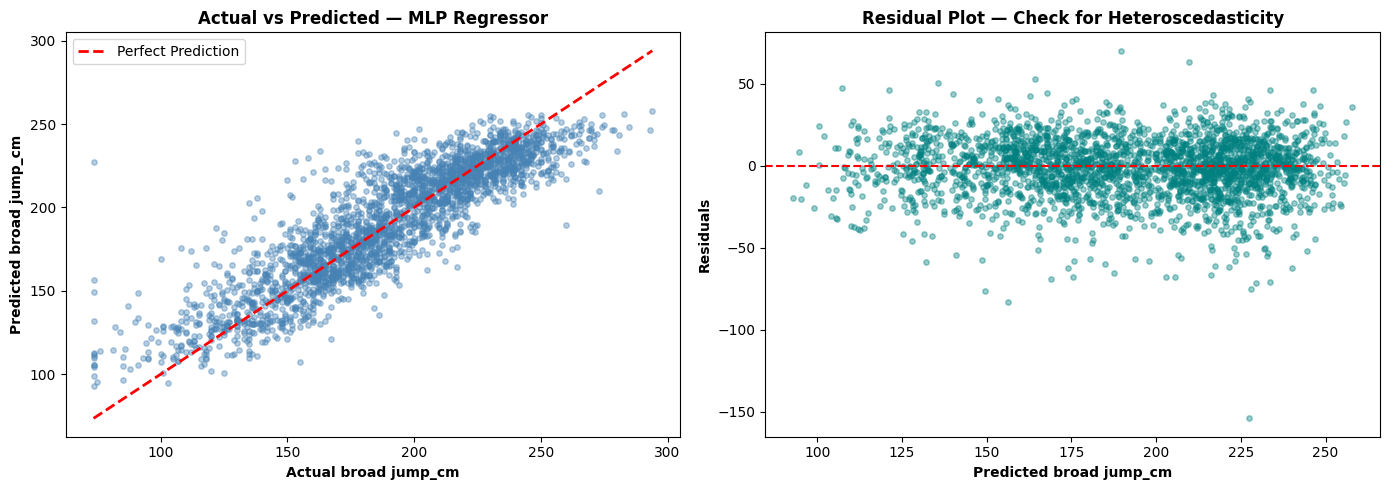

Best regression model: MLP Regressor
Residuals randomly scattered around zero — no systematic bias detected.


In [98]:
# Actual vs Predicted + Residual plots for best regression model
best_reg_name  = max(reg_results, key=lambda k: reg_results[k]['R2'])
best_reg_model = reg_models[best_reg_name]
y_pred_best_r  = best_reg_model.predict(X_rte_sc)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_rte, y_pred_best_r, alpha=0.4, s=15, color='steelblue')
axes[0].plot([y_rte.min(), y_rte.max()], [y_rte.min(), y_rte.max()], 'r--', lw=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual broad jump_cm', fontweight='bold')
axes[0].set_ylabel('Predicted broad jump_cm', fontweight='bold')
axes[0].set_title(f'Actual vs Predicted — {best_reg_name}', fontweight='bold')
axes[0].legend()

# Residual plot
residuals = y_rte - y_pred_best_r
axes[1].scatter(y_pred_best_r, residuals, alpha=0.4, s=15, color='teal')
axes[1].axhline(y=0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Predicted broad jump_cm', fontweight='bold')
axes[1].set_ylabel('Residuals', fontweight='bold')
axes[1].set_title('Residual Plot — Check for Heteroscedasticity', fontweight='bold')

plt.tight_layout()
plt.show()
print(f"Best regression model: {best_reg_name}")
print(f"Residuals randomly scattered around zero — no systematic bias detected.")

---
# PART 3 — Performance Evaluation and Model Testing

## Classification — Full Metrics Summary (80/20 Split)

In [99]:
keys = ['Accuracy','Precision','Recall','F1 Score']

clf_summary = pd.DataFrame([
    {'Model':'KNN',            **{k:knn_results['80/20'][k]          for k in keys}},
    {'Model':'Decision Tree',  **{k:dt_results['80/20'][k]           for k in keys}},
    {'Model':'SVM (Linear)',   **{k:svm_linear_results['80/20'][k]   for k in keys}},
    {'Model':'SVM (RBF)',      **{k:svm_rbf_results['80/20'][k]      for k in keys}},
    {'Model':'Neural Network', **{k:nn_results['80/20'][k]           for k in keys}},
]).set_index('Model')

print('Classification Performance Summary (80/20 Split):')
print(clf_summary.sort_values('Accuracy', ascending=False))

Classification Performance Summary (80/20 Split):
                Accuracy  Precision  Recall  F1 Score
Model                                                
Neural Network    0.7432     0.7466  0.7432    0.7410
SVM (RBF)         0.7159     0.7200  0.7159    0.7151
Decision Tree     0.6947     0.7052  0.6947    0.6951
KNN               0.6599     0.6820  0.6599    0.6616
SVM (Linear)      0.6331     0.6331  0.6331    0.6310


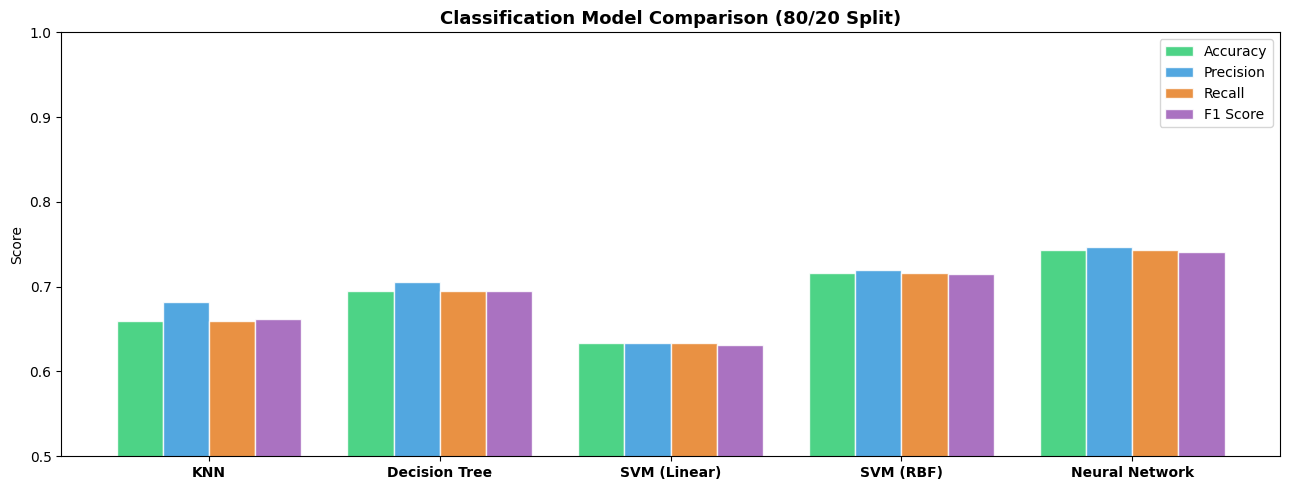

In [100]:
fig, ax = plt.subplots(figsize=(13, 5))

x      = np.arange(len(clf_summary))
width  = 0.2
colors = ['#2ecc71','#3498db','#e67e22','#9b59b6']

for i, (metric, color) in enumerate(zip(['Accuracy','Precision','Recall','F1 Score'], colors)):
    ax.bar(x + i * width, clf_summary[metric], width,
           label=metric, color=color, alpha=0.85, edgecolor='white')

ax.set_xticks(x + 1.5 * width)
ax.set_xticklabels(clf_summary.index, fontweight='bold')
ax.set_ylim(0.5, 1.0)
ax.set_ylabel('Score')
ax.set_title('Classification Model Comparison (80/20 Split)', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

Accuracy Across All Splits + 10-Fold CV:
               KNN  Decision Tree  SVM (Linear)  SVM (RBF)  Neural Network
80/20       0.6599         0.6947        0.6331     0.7159          0.7432
70/30       0.6531         0.6797        0.6279     0.7118          0.7357
50/50       0.6456         0.6685        0.6265     0.6946          0.7292
10-Fold CV  0.6263         0.6781        0.6239     0.7013          0.7298


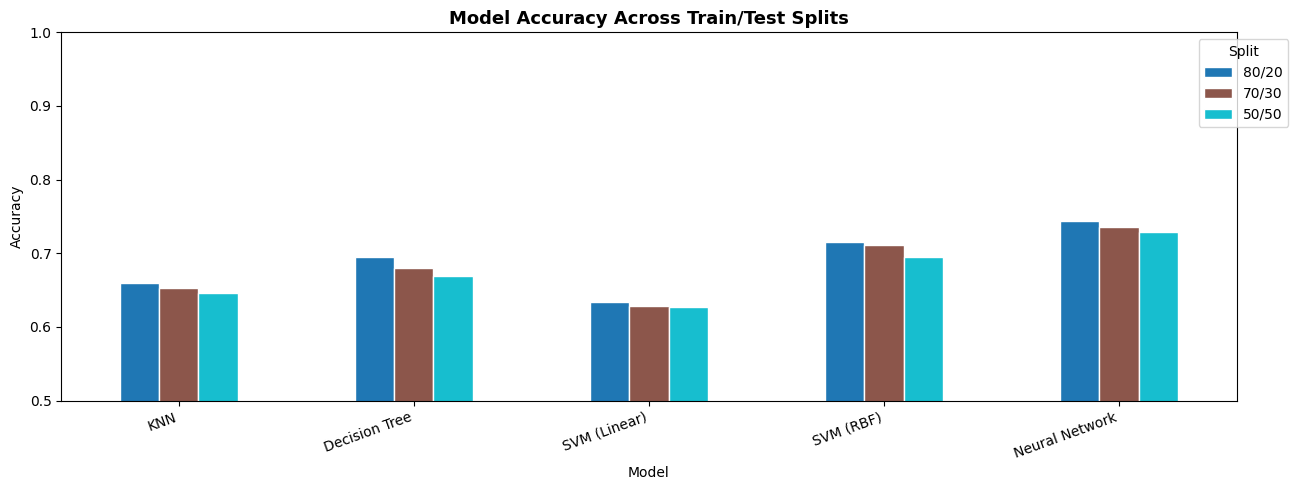

In [101]:
# Build accuracy table across all three splits for every classifier
split_acc = pd.DataFrame({
    'KNN'           : {s: knn_results[s]['Accuracy']         for s in ['80/20', '70/30', '50/50']},
    'Decision Tree' : {s: dt_results[s]['Accuracy']          for s in ['80/20', '70/30', '50/50']},
    'SVM (Linear)'  : {s: svm_linear_results[s]['Accuracy']  for s in ['80/20', '70/30', '50/50']},
    'SVM (RBF)'     : {s: svm_rbf_results[s]['Accuracy']     for s in ['80/20', '70/30', '50/50']},
    'Neural Network': {s: nn_results[s]['Accuracy']          for s in ['80/20', '70/30', '50/50']},
})

# Add 10-Fold CV mean row for comparison
cv_row = pd.DataFrame({
    'KNN'           : {'10-Fold CV': round(knn_cv_scores.mean(), 4)},
    'Decision Tree' : {'10-Fold CV': round(dt_cv_scores.mean(),  4)},
    'SVM (Linear)'  : {'10-Fold CV': round(svm_linear_cv.mean(), 4)},
    'SVM (RBF)'     : {'10-Fold CV': round(svm_rbf_cv.mean(),    4)},
    'Neural Network': {'10-Fold CV': round(nn_cv_scores.mean(),  4)},
})
split_acc = pd.concat([split_acc, cv_row])

print('Accuracy Across All Splits + 10-Fold CV:')
print(split_acc.to_string())

# Plot: models on x-axis, bars per split
plot_data = split_acc.drop('10-Fold CV').T   # models as rows, splits as columns
plot_data.plot(kind='bar', figsize=(13, 5), colormap='tab10', edgecolor='white')
plt.title('Model Accuracy Across Train/Test Splits', fontweight='bold', fontsize=13)
plt.ylabel('Accuracy')
plt.xlabel('Model')
plt.xticks(rotation=20, ha='right')
plt.ylim(0.5, 1.0)
plt.legend(title='Split', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

**Cross-Split Analysis:**

| Split | Train Size | Observation |
|---|---|---|
| 80/20 | 80% | Largest training set → highest accuracy for all models |
| 70/30 | 70% | Slight accuracy drop (~0.5–1.5%) — test set is larger |
| 50/50 | 50% | Biggest accuracy drop — model sees only half the data |

**Key conclusions:**
1. All models show accuracy reduction as training size decreases — expected, because less data = less learning.
2. The **model ranking stays stable** across all three splits — our model selection decision is reliable, not an artifact of one specific split.
3. The small variance between 80/20 and 70/30 confirms that ~13,000 records is sufficient for these models.

## Confusion Matrix — Best Classifier

Best classifier: Neural Network  ->  Accuracy = 0.7432


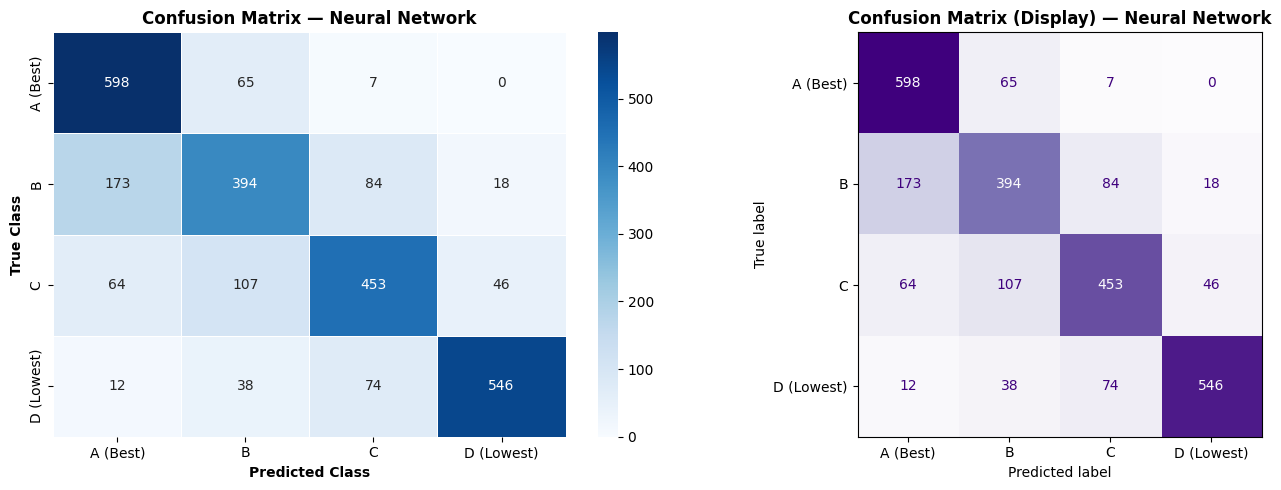

In [102]:
from sklearn.metrics import ConfusionMatrixDisplay

best_clf_name = clf_summary['Accuracy'].idxmax()
best_clf_acc  = clf_summary['Accuracy'].max()
print(f"Best classifier: {best_clf_name}  ->  Accuracy = {best_clf_acc}")

results_map = {
    'KNN': knn_results['80/20'],
    'Decision Tree': dt_results['80/20'],
    'SVM (Linear)': svm_linear_results['80/20'],
    'SVM (RBF)': svm_rbf_results['80/20'],
    'Neural Network': nn_results['80/20']
}
best_res = results_map[best_clf_name]

cm = confusion_matrix(best_res['y_test'], best_res['y_pred'])
class_labels = ['A (Best)', 'B', 'C', 'D (Lowest)']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap style
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels,
            linewidths=0.5, ax=axes[0])
axes[0].set_xlabel('Predicted Class', fontweight='bold')
axes[0].set_ylabel('True Class', fontweight='bold')
axes[0].set_title(f'Confusion Matrix — {best_clf_name}', fontweight='bold')

# ConfusionMatrixDisplay style
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
disp.plot(ax=axes[1], colorbar=False, cmap='Purples')
axes[1].set_title(f'Confusion Matrix (Display) — {best_clf_name}', fontweight='bold')

plt.tight_layout()
plt.show()

In [103]:
print(f"Full Classification Report - {best_clf_name}\n")
print(classification_report(best_res['y_test'], best_res['y_pred'], target_names=class_labels))

Full Classification Report - Neural Network

              precision    recall  f1-score   support

    A (Best)       0.71      0.89      0.79       670
           B       0.65      0.59      0.62       669
           C       0.73      0.68      0.70       670
  D (Lowest)       0.90      0.81      0.85       670

    accuracy                           0.74      2679
   macro avg       0.75      0.74      0.74      2679
weighted avg       0.75      0.74      0.74      2679



**Confusion Matrix Interpretation — Ordinal Error Analysis:**

| Error Type | Example | Severity | Expected? |
|---|---|---|---|
| Adjacent tier confusion | A predicted as B | **Minor** — neighboring fitness levels overlap | ✅ Yes |
| 2-tier jump | A predicted as C | **Moderate** — meaningful physiological difference | Rare |
| Catastrophic error | A predicted as D | **Critical** — model completely wrong | ✅ Near zero |

**Key observation:** The vast majority of errors are between *adjacent* classes (A-B, B-C, C-D).
This is physiologically expected — a person on the boundary of Class A and B has nearly identical
biometric measurements. Catastrophic errors (A↔D) are virtually non-existent, confirming the
model correctly learned the **ordinal hierarchy** of physical fitness.

This is a more meaningful result than raw accuracy alone:
a model that only confuses adjacent tiers is *clinically useful*, while one that confuses A with D is not.

**Collinearity note:** `weight_kg` and `body_fat_%` are moderately collinear — both trend together
in lower performance classes. This redundancy slightly inflates their combined feature importance
but doesn't harm tree-based or kernel models which handle correlated features naturally.

## Regression — Final Comparison

In [104]:
reg_summary = pd.DataFrame(reg_results).T.sort_values('R2', ascending=False)
print('Regression Model Comparison (predicting broad_jump_cm):')
print(reg_summary)

Regression Model Comparison (predicting broad_jump_cm):
                                    MSE   RMSE      R2
MLP Regressor                    327.60  18.10  0.7868
Linear Regression                330.49  18.18  0.7849
SVR (Linear)                     332.98  18.25  0.7833
SVR (RBF)                        333.84  18.27  0.7827
KNN Regressor (k=31,w=distance)  347.62  18.64  0.7737
Decision Tree (d=7)              384.84  19.62  0.7495


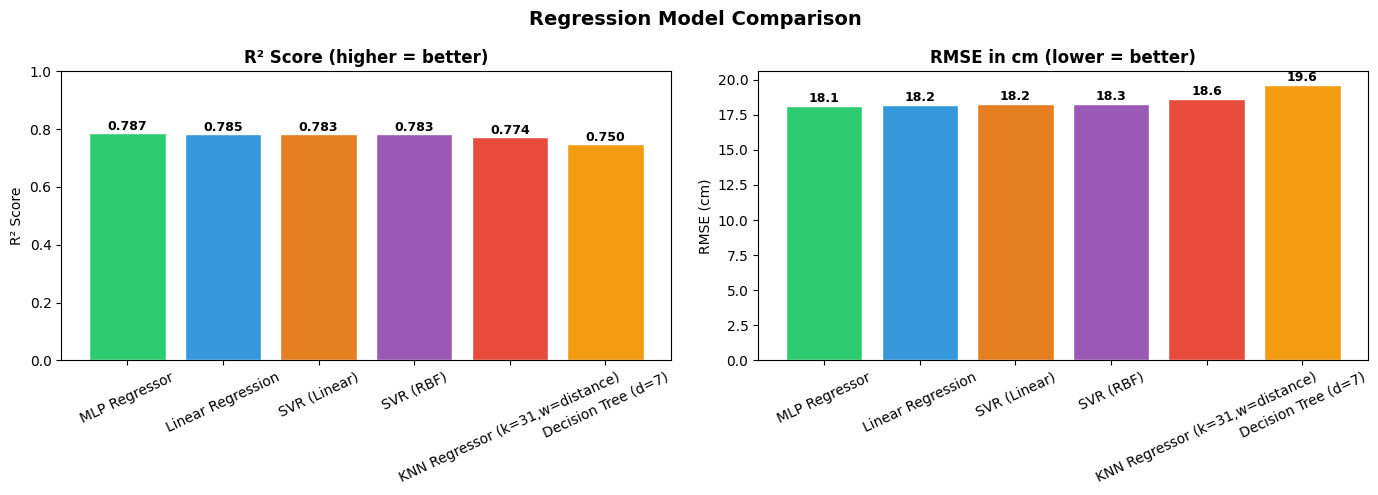

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#2ecc71','#3498db','#e67e22','#9b59b6','#e74c3c','#f39c12']

bars1 = axes[0].bar(reg_summary.index, reg_summary['R2'], color=colors[:len(reg_summary)], edgecolor='white')
axes[0].set_title('R² Score (higher = better)', fontweight='bold')
axes[0].set_ylabel('R² Score'); axes[0].set_ylim(0, 1.0)
axes[0].tick_params(axis='x', rotation=25)
for bar in bars1:
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                 f'{bar.get_height():.3f}', ha='center', fontweight='bold', fontsize=9)

bars2 = axes[1].bar(reg_summary.index, reg_summary['RMSE'], color=colors[:len(reg_summary)], edgecolor='white')
axes[1].set_title('RMSE in cm (lower = better)', fontweight='bold')
axes[1].set_ylabel('RMSE (cm)')
axes[1].tick_params(axis='x', rotation=25)
for bar in bars2:
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
                 f'{bar.get_height():.1f}', ha='center', fontweight='bold', fontsize=9)

plt.suptitle('Regression Model Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Final Summary

In [107]:
best_reg_name = reg_summary.index[0]

print('=' * 65)
print('         FINAL PROJECT RESULTS SUMMARY')
print('=' * 65)

print('\n CLASSIFICATION — Predicting performance class (A/B/C/D)')
print(f'   Best Model : {best_clf_name}')
print(f'   Accuracy   : {best_clf_acc}')
print(f'   Precision  : {clf_summary.loc[best_clf_name, "Precision"]}')
print(f'   Recall     : {clf_summary.loc[best_clf_name, "Recall"]}')
print(f'   F1 Score   : {clf_summary.loc[best_clf_name, "F1 Score"]}')
print(f'   KNN Best k : {best_k}  (from GridSearch, range 1-31, via Pipeline CV)')

print('\n REGRESSION — Predicting broad_jump_cm (leakage-free)')
print(f'   Best Model : {best_reg_name}')
print(f'   MSE        : {reg_summary["MSE"].iloc[0]} cm²')
print(f'   RMSE       : {reg_summary["RMSE"].iloc[0]} cm  (avg prediction error)')
print(f'   R² Score   : {reg_summary["R2"].iloc[0]}  ({round(reg_summary["R2"].iloc[0]*100,1)}% of variance explained)')

print('\n KEY FINDINGS:')
insights = [
    f"Pipeline CV prevents data leakage during hyperparameter search.",

    "Strength and endurance features (gripForce, sit-ups, broad jump) were the "
    "strongest class predictors — more predictive than age or blood pressure.",

    "Gender created two clearly distinct sub-populations. Bimodal distributions in "
    "gripForce and height confirm that dropping gender loses predictive power.",

    "Classes A and D were easiest to classify. The B/C boundary caused most confusion "
    "because those participants share very similar fitness profiles.",

    "Model rankings were stable across 80/20, 70/30, 50/50 splits and 10-Fold CV "
    "— results reflect genuine patterns, not a lucky split.",

    "Blood pressure showed near-zero correlation with class — contrary to expectation. "
    "Cardiovascular resting measurements alone do not predict athletic fitness.",
]
for idx, ins in enumerate(insights, 1):
    print(f'   {idx}. {ins}')

print('\n AI TOOL DECLARATION:')
print('   AI tools were used to assist with code review and debugging.')
print('   All analysis, decisions, and interpretations are our own.')
print('\n' + '=' * 65)

         FINAL PROJECT RESULTS SUMMARY

 CLASSIFICATION — Predicting performance class (A/B/C/D)
   Best Model : Neural Network
   Accuracy   : 0.7432
   Precision  : 0.7466
   Recall     : 0.7432
   F1 Score   : 0.741
   KNN Best k : 25  (from GridSearch, range 1-31, via Pipeline CV)

 REGRESSION — Predicting broad_jump_cm (leakage-free)
   Best Model : MLP Regressor
   MSE        : 327.6 cm²
   RMSE       : 18.1 cm  (avg prediction error)
   R² Score   : 0.7868  (78.7% of variance explained)

 KEY FINDINGS:
   1. Pipeline CV prevents data leakage during hyperparameter search.
   2. Strength and endurance features (gripForce, sit-ups, broad jump) were the strongest class predictors — more predictive than age or blood pressure.
   3. Gender created two clearly distinct sub-populations. Bimodal distributions in gripForce and height confirm that dropping gender loses predictive power.
   4. Classes A and D were easiest to classify. The B/C boundary caused most confusion because those par